# F Cipriani
# Curso de Machine Learning 2026
# Parte 2A — Preparación y evaluación

Este cuaderno toma el archivo `dataset_limpio.csv` que produjo la **Parte 1**. No hace falta tenerlo descargado:
por defecto el cuaderno lo lee directamente del repositorio de GitHub del proyecto, así que se abre y se ejecuta. El punto 0.2 explica las dos alternativas.

**Qué hace este cuaderno**

1. Carga el dataset limpio y verifica que sea lo que espera.
2. Lo transforma: codifica la etiqueta y muestra el escalado.
3. Divide en entrenamiento y prueba, y demuestra por qué una sola división no alcanza.
4. Explica y demuestra dos problemas que arruinan cualquier evaluación: la **fuga de información** y el **sobreajuste**.
5. Llega a la validación cruzada, que es la forma de medir que usa toda la Parte 2B.
6. Exporta el estado para que la Parte 2B siga desde ahí.

**Por qué son dos cuadernos**

Por uan cuestion de simplicidad y conceptualmente son dos cosas distintas:

*  Parte 2A **define cómo se mide**
*  Parte 2B **mide usando distintos modelos**

**Las librerías se importan por bloques**, justo antes de la sección que las usa, en lugar de todas juntas al principio. Así se ve qué necesita cada etapa, y cada cuaderno carga solamente lo que usa.

---

# Índice — Parte 2A

### Parte 0 — Preliminares
- [0.1 Qué necesita este cuaderno](#sec-0-1)
- [0.2 Cargar el dataset limpio](#sec-0-2)
- [0.3 Verificación de entrada](#sec-0-3)
- [0.4 Configuración global](#sec-0-4)
- [0.5 Librerías de gráficos y estilo](#sec-0-5)

### 1. ¿Qué es Machine Learning? Dónde estamos parados
- [1.1 Aprendizaje supervisado y no supervisado](#sec-1-1)
- [1.2 Regresión y clasificación: dos preguntas distintas](#sec-1-2)
- [1.3 Diagnóstico de nuestro problema](#sec-1-3)
- [1.4 Los cuatro modelos que vamos a usar](#sec-1-4)

### 2. Transformación de datos
- [2.1 Feature engineering](#sec-2-1)
- [2.2 Codificación de la variable categórica](#sec-2-2)
- [2.3 Normalización y estandarización](#sec-2-3)
- [2.4 Las matrices X e y](#sec-2-4)
- [2.5 Reducción de dimensionalidad: PCA](#sec-2-5)

### 3. División del dataset: entrenamiento y prueba
- [3.1 Por qué hay que dividir](#sec-3-1)
- [3.2 La división 80/20 estratificada](#sec-3-2)
- [3.3 La fragilidad de una sola división](#sec-3-3)

### 4. Fuga de información (data leakage)
- [4.1 Qué es](#sec-4-1)
- [4.2 Por qué es tan grave: el síntoma es que no hay síntoma](#sec-4-2)
- [4.3 Las siete formas en que se cuela](#sec-4-3)
- [4.4 Demostración 1 — el escalador que mira de más](#sec-4-4)
- [4.5 Demostración 2 — "predecir" ruido puro muy por encima del azar](#sec-4-5)
- [4.6 El Pipeline como antídoto](#sec-4-6)
- [4.7 Lista de control](#sec-4-7)

### 5. Overfitting y underfitting
- [5.1 Qué es cada uno](#sec-5-1)
- [5.2 El compromiso sesgo-varianza](#sec-5-2)
- [5.3 Las señales: tabla de diagnóstico](#sec-5-3)
- [5.4 Las cuatro formas de detectarlo](#sec-5-4)
- [5.5 Cómo se mide: la brecha y sus umbrales](#sec-5-5)
- [5.6 Qué hacer con cada uno](#sec-5-6)
- [5.7 En código: tres niveles de complejidad](#sec-5-7)
- [5.8 La curva de validación](#sec-5-8)
- [5.9 La curva de aprendizaje](#sec-5-9)

### 6. Validación cruzada K-Fold
- [6.1 Cómo funciona](#sec-6-1)
- [6.2 Cuántos pliegues, y por qué acá no es opcional](#sec-6-2)
- [6.3 El esquema estratificado](#sec-6-3)
- [6.4 Una división contra validación cruzada](#sec-6-4)

### Exportar el estado para la Parte 2B
- [Los archivos que deja este cuaderno](#sec-export-1)
- [Cómo llevártelos](#sec-export-2)

### Cierre
- [Resumen de lo hecho](#sec-cierre)

**Los modelos** y la comparativa final están en la **Parte 2B**, puntos 7 a 22.

---
# Parte 0 — Preliminares

<a id="sec-0-1"></a>
## 0.1 Qué necesita este cuaderno

**La entrada:** el archivo `dataset_limpio.csv` que dejó la Parte 1. Tiene 171 filas y 8 columnas:
`TAG` con las clases `AFI` y `NEG`, y siete columnas numéricas.

**Qué se le hizo en la Parte 1**

  * Verificado que no hay valores faltantes
  * Verificado que no hay duplicados ni contradicciones
  * Verificado que los tipos son correctos
  * Verificado que los rangos son posibles
  * Detectados los outliers, y conservados a propósito

**Qué vamos a hacer en esta Parte 2A**  

  * Codificar la etiqueta a 0 y 1
  * Escalar las variables
  * Dividir en entrenamiento y prueba
  * Entrenar y comparar

Codificar y escalar dependen de qué modelo se vaya a usar, y —como vamos a ver en el punto 4— tienen que aplicarse adentro del pipeline, después de la división, para no arruinar la evaluación.

<a id="sec-0-2"></a>
## 0.2 Cargar el dataset limpio

Dos formas de traer el archivo. La que quede sin comentar tiene que dejar la ruta en la variable
`RUTA_DATOS`.

| Cómo | Cuándo conviene |
|---|---|
| **A** — Desde GitHub | Siempre que haya conexión. Es la que queda **activa**: no hay que descargar ni subir nada |
| **B** — Subir el archivo a mano | Si queremos trabajar con tu propia versión del CSV, o no tenés acceso al repositorio |

**Sobre la opción A.** GitHub tiene dos direcciones para cada archivo: la de la página web, que
devuelve el archivo *mostrado dentro del sitio* —es decir, HTML—, y la de `raw.githubusercontent.com`,
que devuelve el contenido crudo. Pandas necesita la segunda. La celda la arma sola a partir del
usuario, el repositorio y la rama, así que para apuntar a otro repositorio alcanza con cambiar esas
tres variables. El repositorio tiene que ser público.

**Sobre la opción B.** `files.upload()` abre un diálogo del navegador para elegir el archivo desde
tu máquina. Solo funciona en Colab, y el archivo vive en la sesión: cuando el entorno se reinicia
hay que volver a subirlo.

In [26]:
NOMBRE_ARCHIVO = "dataset_limpio.csv"

# ---------------------------------------------------------------------
# OPCIÓN A — Desde GitHub   (ACTIVA)
# ---------------------------------------------------------------------
USUARIO = "FerCipriani"            # <-- cambiar si usás otro repositorio
REPO    = "CursoML_Proyecto_IVE"   # <-- cambiar si usás otro repositorio
RAMA    = "main"                   # GitHub usa 'main' por defecto

RUTA_DATOS = f"https://raw.githubusercontent.com/{USUARIO}/{REPO}/{RAMA}/{NOMBRE_ARCHIVO}"

# ---------------------------------------------------------------------
# OPCIÓN B — Subir el archivo a mano   (solo Colab)
# ---------------------------------------------------------------------
# from google.colab import files
# RUTA_DATOS = list(files.upload().keys())[0]

print(f"Ruta configurada: {RUTA_DATOS}")

Ruta configurada: https://raw.githubusercontent.com/FerCipriani/CursoML_Proyecto_IVE/main/dataset_limpio.csv


Ahora las librerías de datos y la lectura.

La celda detecta sola si la ruta termina en `.csv` o en `.xlsx` y usa la función que corresponde,
así que sirve igual si en vez del CSV limpio le pasás un Excel. Y si la lectura falla —típicamente
porque no hay conexión, o porque se cambió el nombre del repositorio— reintenta con un archivo
local del mismo nombre antes de darse por vencida.

In [27]:
import numpy as np
import pandas as pd

print(f"NumPy  : {np.__version__}")
print(f"Pandas : {pd.__version__}")
print()

# --- Lectura: elige la función según la extensión ---
def leer_datos(ruta):
    if str(ruta).lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(ruta)
    return pd.read_csv(ruta)

try:
    df = leer_datos(RUTA_DATOS)
except Exception as error:
    print(f"[AVISO] No se pudo leer: {RUTA_DATOS}")
    print(f"        {type(error).__name__}: {str(error)[:110]}")
    print(f"        Reintentando con el archivo local '{NOMBRE_ARCHIVO}'...")
    df = leer_datos(NOMBRE_ARCHIVO)
    RUTA_DATOS = NOMBRE_ARCHIVO

print("=" * 70)
print("  LECTURA")
print("=" * 70)
print(f"  Archivo     : {RUTA_DATOS}")
print(f"  Dimensiones : {df.shape[0]} filas x {df.shape[1]} columnas")
print()
display(df.head())

NumPy  : 2.4.6
Pandas : 2.2.3

  LECTURA
  Archivo     : https://raw.githubusercontent.com/FerCipriani/CursoML_Proyecto_IVE/main/dataset_limpio.csv
  Dimensiones : 171 filas x 8 columnas



,TAG,T0,T1,T2,T3,T4,T5,T6
0,AFI,0.0228,0.2070,0.3818,0.2747,0.0003,0.1131,0.0003
1,AFI,0.0068,0.0040,0.0494,0.1765,0.0312,0.4422,0.2899
2,AFI,0.1273,0.0005,0.1998,0.3339,0.0259,0.0150,0.2976
3,AFI,0.2085,0.1278,0.0905,0.2023,0.1433,0.0004,0.2272
4,AFI,0.0004,0.3938,0.1926,0.2707,0.0004,0.0004,0.1416


<a id="sec-0-3"></a>
## 0.3 Verificación de entrada

La Parte 1 dejó el dataset auditado, pero este cuaderno **no da eso por sentado**. Repite los
controles esenciales antes de tocar nada.

No es desconfianza gratuita: en un pipeline real, la etapa que consume un archivo no sabe quién lo
generó ni si se modificó en el camino. Alguien pudo haber abierto el CSV en Excel y guardado con
otro separador decimal; pudo haberse subido una versión vieja; pudo haberse leído la hoja
equivocada.

Los cinco controles:

*  Nulos
*  Duplicados
*  Tipos
*  Rangos
*  Que la etiqueta tenga exactamente dos clases

In [28]:
print("=" * 78)
print("  VERIFICACIÓN DE ENTRADA")
print("=" * 78)

COLUMNA_OBJETIVO = "TAG"
objetivo = COLUMNA_OBJETIVO

problemas = []

# 1. ¿Está la columna objetivo?
if objetivo not in df.columns:
    problemas.append(f"no existe la columna objetivo '{objetivo}'")
    print(f"  [ERROR] No está la columna '{objetivo}'. Columnas: {list(df.columns)}")
else:
    print(f"  [OK] Columna objetivo '{objetivo}' presente")

# 2. Predictoras numéricas
predictoras = [c for c in df.columns
               if c != objetivo and pd.api.types.is_numeric_dtype(df[c])]
no_numericas = [c for c in df.columns if c != objetivo and c not in predictoras]
print(f"  [OK] Variables predictoras numéricas: {len(predictoras)}")
if no_numericas:
    problemas.append(f"columnas no numéricas fuera del objetivo: {no_numericas}")
    print(f"  [AVISO] Columnas no numéricas que quedan fuera: {no_numericas}")

# 3. Nulos
nulos = int(df.isna().sum().sum())
if nulos:
    problemas.append(f"{nulos} valores faltantes")
    print(f"  [ERROR] Hay {nulos} valores faltantes. Volvé a la Parte 1.")
else:
    print("  [OK] Sin valores faltantes")

# 4. Duplicados
duplicados = int(df.duplicated().sum())
if duplicados:
    problemas.append(f"{duplicados} filas duplicadas")
    print(f"  [AVISO] Hay {duplicados} filas duplicadas.")
else:
    print("  [OK] Sin filas duplicadas")

# 5. Clases
clases = sorted(df[objetivo].astype(str).unique())
if len(clases) != 2:
    problemas.append(f"la etiqueta tiene {len(clases)} clases, no 2")
    print(f"  [ERROR] La etiqueta tiene {len(clases)} clases: {clases}")
    print("          Este cuaderno está armado para clasificación BINARIA.")
else:
    print(f"  [OK] Clasificación binaria: {clases}")

# 6. Rangos
if predictoras:
    minimo = df[predictoras].to_numpy().min()
    maximo = df[predictoras].to_numpy().max()
    print(f"  [OK] Rango de las predictoras: {minimo:.6f} a {maximo:.6f}")
    sumas = df[predictoras].sum(axis=1)
    if np.allclose(sumas, 1.0, atol=1e-6):
        print("  [OK] Las filas suman 1: las variables son proporciones de un total fijo")

print()
if problemas:
    print(f"  RESULTADO: {len(problemas)} problema(s) -> {problemas}")
    print("  Revisá la Parte 1 antes de seguir.")
else:
    print("  RESULTADO: el dataset pasó todos los controles. Se puede modelar.")

print()
print(f"  Reparto de clases:")
conteo = df[objetivo].value_counts()
proporcion = df[objetivo].value_counts(normalize=True)
for clase in conteo.index:
    print(f"    {clase:>5} : {conteo[clase]:>4} casos ({proporcion[clase]:.1%})")
linea_base = proporcion.max()
clase_mayoritaria = proporcion.idxmax()
print(f"  LÍNEA DE BASE: {linea_base:.2%}  (responder siempre '{clase_mayoritaria}')")

  VERIFICACIÓN DE ENTRADA
  [OK] Columna objetivo 'TAG' presente
  [OK] Variables predictoras numéricas: 7
  [OK] Sin valores faltantes
  [OK] Sin filas duplicadas
  [OK] Clasificación binaria: ['AFI', 'NEG']
  [OK] Rango de las predictoras: 0.000120 a 0.714286
  [OK] Las filas suman 1: las variables son proporciones de un total fijo

  RESULTADO: el dataset pasó todos los controles. Se puede modelar.

  Reparto de clases:
      AFI :   95 casos (55.6%)
      NEG :   76 casos (44.4%)
  LÍNEA DE BASE: 55.56%  (responder siempre 'AFI')


<a id="sec-0-4"></a>
## 0.4 Configuración global

Todos los valores que se podrían querer cambiar, juntos y con nombre propio.

Dos merecen explicación:

- **`SEMILLA`** — varios procedimientos que vamos a usar tienen un componente aleatorio: cómo se
  mezclan las filas antes de partirlas, qué variables mira un árbol en cada nodo, qué muestra le
  toca a cada árbol del bosque. Fijar la semilla hace que esa aleatoriedad sea siempre la misma y
  que el cuaderno dé el mismo resultado cada vez que se corre. Sin semilla fija, los números
  cambian en cada ejecución y no se puede comparar nada.

- **`CLASE_POSITIVA`** — en clasificación binaria hay que decidir cuál de las dos clases es "la
  positiva". Esa elección **no** afecta el accuracy, pero **sí** afecta la precisión, el recall y
  el F1-score, porque esas métricas están definidas desde el punto de vista de la clase positiva.
  La elección es arbitraria; lo que no es arbitrario es dejarla escrita.

In [29]:
# --- Reproducibilidad ---
SEMILLA = 65

# --- El problema ---
CLASE_POSITIVA = "AFI"    # la otra pasa a ser la negativa

# --- Validación cruzada ---
N_PLIEGUES = 10

# --- Formato de la salida ---
import warnings
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
warnings.filterwarnings("ignore")

clase_negativa = [c for c in clases if c != CLASE_POSITIVA][0]

print("Configuración cargada.")
print(f"  Semilla           : {SEMILLA}")
print(f"  Clase positiva    : {CLASE_POSITIVA}  (la negativa es {clase_negativa})")
print(f"  Pliegues (K-Fold) : {N_PLIEGUES}")
print(f"  Umbral sobreajuste: {BRECHA_SOBREAJUSTE}")
print(f"  Umbral desvío     : {DESVIO_INESTABLE}")
print(f"  Umbral subajuste  : {SCORE_SUBAJUSTE}")

Configuración cargada.
  Semilla           : 65
  Clase positiva    : AFI  (la negativa es NEG)
  Pliegues (K-Fold) : 10
  Umbral sobreajuste: 0.1
  Umbral desvío     : 0.08
  Umbral subajuste  : 0.7


<a id="sec-0-5"></a>
## 0.5 Librerías de gráficos y estilo

Este cuaderno grafica en casi todas sus secciones, así que las librerías de visualización y el estilo se configuran acá.

- **Matplotlib** — la base. Controla cada detalle: ejes, colores, leyendas.
- **Seaborn** — construida encima. Menos código para gráficos estadísticos.

Fijamos también un color por clase para que los gráficos de todo el cuaderno se
puedan comparar de un vistazo.

In [30]:
# --- Librerías de gráficos ---
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# --- Estilo global ---
sns.set_theme(style="whitegrid", palette="deep")
mpl.rcParams["figure.figsize"] = (10, 5)
mpl.rcParams["figure.dpi"] = 110
mpl.rcParams["axes.titlesize"] = 12
mpl.rcParams["axes.titleweight"] = "bold"
mpl.rcParams["font.size"] = 10

# --- Colores fijos ---
COLOR_CLASE = {"AFI": "#1f77b4", "NEG": "#d62728"}

print(f"Matplotlib : {mpl.__version__}")
print(f"Seaborn    : {sns.__version__}")
print()
print("Colores por clase:", COLOR_CLASE)

Matplotlib : 3.10.0
Seaborn    : 0.13.2

Colores por clase: {'AFI': '#1f77b4', 'NEG': '#d62728'}


---
# 1. ¿Qué es Machine Learning? Dónde estamos parados

<a id="sec-1-1"></a>
## 1.1 Aprendizaje supervisado y no supervisado

En el enfoque clásico, una persona define las reglas: *si el asunto contiene tal palabra y el remitente está en tal lista, entonces es
spam*.

En Machine Learning el sistema **descubre las reglas solo**, a partir de ejemplos ya resueltos. Y lo que se busca no es que memorice esos ejemplos, sino que **generalice**: que funcione con casos nuevos que nunca vio.


**Los dos tipos principales de aprendizaje**

- **Supervisado.** Los datos vienen con la respuesta conocida (una "etiqueta"). El modelo busca la
  relación entre las variables de entrada y esa etiqueta. Se divide a su vez en **regresión**
  (etiqueta numérica continua) y **clasificación** (etiqueta categórica).
- **No supervisado.** No hay etiqueta. El objetivo es descubrir estructura oculta en los datos. El
  caso típico es el *clustering*: agrupar casos parecidos entre sí.

La diferencia está en si el dataset tiene o no etiquetas que guíen al modelo. El nuestro las tiene:
la columna `TAG`. Es un problema **supervisado**.

**El ciclo de vida de un proyecto**

| Etapa | Dónde está |
|---|---|
| 1. Recolección y comprensión de los datos | Parte 1, puntos 0.2 y 1 |
| 2. Análisis exploratorio (EDA) y limpieza | Parte 1, puntos 2 y 3 |
| 3. Preprocesamiento y preparación | **Parte 2A, punto 2** |
| 4. Selección y entrenamiento del modelo | **Parte 2B, puntos 8 a 11** |
| 5. Evaluación del modelo | **Parte 2A punto 6, Parte 2B punto 12** |
| 6. Implementación y monitoreo | fuera del alcance de estos cuadernos |
| 7. Mantenimiento y mejora continua | fuera del alcance de estos cuadernos |

Entre las dos partes cubrimos las etapas 1 a 5. Las dos últimas empiezan cuando el modelo sale a
producción.

<a id="sec-1-2"></a>
## 1.2 Regresión y clasificación: dos preguntas distintas

Los dos son problemas de aprendizaje supervisado —los dos parten de datos con la respuesta
conocida— pero responden preguntas de naturaleza distinta.

### Regresión: la pregunta es "¿cuánto?"

La variable objetivo es un **número continuo**: un precio, una cantidad de días, una temperatura,
un monto. La salida del modelo puede ser cualquier valor real.

El modelo básico es la **regresión lineal**, que ajusta la recta `y = a·x + b` que mejor pasa entre
los puntos —o su versión con varias variables,
`y = a₁·x₁ + a₂·x₂ + … + aₙ·xₙ + b`—. Se evalúa con métricas que miden *cuán lejos* quedó de la
realidad:

| Métrica | Qué mide | Cuándo conviene |
|---|---|---|
| **MAE** (error absoluto medio) | El promedio de los errores, en las unidades originales | Cuando se quiere una idea clara del margen de error: "se equivoca en promedio por $8.500" |
| **MSE** (error cuadrático medio) | Eleva cada error al cuadrado antes de promediar | Cuando los errores grandes son mucho peores que los chicos. Pierde las unidades originales |
| **RMSE** (raíz del MSE) | La raíz cuadrada del anterior | El punto medio: castiga los errores grandes pero recupera las unidades |
| **R²** (coeficiente de determinación) | Qué proporción de la variabilidad explica el modelo | Para saber cuánto aporta el modelo respecto de responder siempre el promedio |

**Ejemplos de regresión:** predecir el precio de una casa según su superficie y ubicación; estimar
cuántos días va a durar una internación; anticipar el monto de los reclamos de un cliente en un
año; calcular el tiempo de entrega de un envío.

### Clasificación: la pregunta es "¿cuál?"

La variable objetivo es una **categoría**. Cuando hay solo dos categorías posibles se llama
**clasificación binaria**, que es nuestro caso. Con tres o más, **multiclase**.

El modelo básico es la **regresión logística** que —a pesar del nombre— no predice un número sino
la **probabilidad** de pertenecer a una clase: calcula una combinación lineal de las variables y la
pasa por una función **sigmoide**, que aplasta cualquier número real al intervalo entre 0 y 1.
Después se aplica un **umbral de corte**, habitualmente 0,5, para convertir esa probabilidad en una
decisión.

Las métricas son completamente distintas, porque ya no medimos distancias sino aciertos y errores:

| Métrica | Qué mide | Cuándo conviene |
|---|---|---|
| **Accuracy** (precisión general) | Qué proporción del total acertó | Cuando las clases están balanceadas |
| **Recall** (sensibilidad) | De los casos que realmente eran positivos, cuántos detectó | Cuando dejar pasar un positivo es caro: diagnóstico médico, detección de fraude |
| **Precisión** | De los que predije positivos, cuántos lo eran | Cuando una falsa alarma es cara: Filtro de spam, deteccion de fraude |
| **F1-score** | La media armónica entre precisión y recall | Cuando no se quiere privilegiar ninguna de las dos, o las clases están desbalanceadas |
| **Matriz de confusión** | El desglose completo de aciertos y errores | Siempre. Es la que muestra *cómo* se equivoca, no solo cuánto |

**Ejemplos de clasificación:** decidir si un correo es spam; predecir si un cliente va a cancelar
la suscripción; determinar si un paciente tiene o no una enfermedad; predecir si un estudiante
aprueba o no el curso.

**En una línea:** si la pregunta es "¿cuánto?", regresión. Si es "¿cuál de estas dos?",
clasificación.

<a id="sec-1-3"></a>
## 1.3 Diagnóstico de nuestro problema

Lo verificamos con código en lugar de afirmarlo: miramos el tipo de la variable objetivo y su
cantidad de valores distintos.

In [31]:
print("=" * 78)
print("  DIAGNÓSTICO DEL PROBLEMA")
print("=" * 78)

es_numerica = pd.api.types.is_numeric_dtype(df[objetivo])
n_valores = df[objetivo].nunique()

print(f"  Variable objetivo      : {objetivo}")
print(f"  Tipo de dato           : {df[objetivo].dtype}")
print(f"  ¿Es numérica continua? : {'sí' if es_numerica and n_valores > 20 else 'no'}")
print(f"  Valores distintos      : {n_valores}  ->  {clases}")
print(f"  Variables predictoras  : {len(predictoras)}, todas numéricas")
print(f"  Observaciones          : {len(df)}")
print()

if es_numerica and n_valores > 20:
    tipo_problema = "REGRESIÓN"
elif n_valores == 2:
    tipo_problema = "CLASIFICACIÓN BINARIA"
else:
    tipo_problema = f"CLASIFICACIÓN MULTICLASE ({n_valores} clases)"

print(f"  TIPO DE PROBLEMA : {tipo_problema}")
print()
print("  La variable objetivo es una etiqueta con dos valores posibles, no un número.")
print("  No tiene sentido preguntarse 'cuánto vale TAG': la pregunta es a cuál de las")
print("  dos clases pertenece cada caso.")
print()
print("  En consecuencia:")
print("    - NO se usa regresión lineal, ni MAE / MSE / RMSE / R².")
print("    - SÍ se usan modelos de clasificación, evaluados con accuracy, precisión,")
print("      recall, F1-score, matriz de confusión y curva ROC.")

  DIAGNÓSTICO DEL PROBLEMA
  Variable objetivo      : TAG
  Tipo de dato           : object
  ¿Es numérica continua? : no
  Valores distintos      : 2  ->  ['AFI', 'NEG']
  Variables predictoras  : 7, todas numéricas
  Observaciones          : 171

  TIPO DE PROBLEMA : CLASIFICACIÓN BINARIA

  La variable objetivo es una etiqueta con dos valores posibles, no un número.
  No tiene sentido preguntarse 'cuánto vale TAG': la pregunta es a cuál de las
  dos clases pertenece cada caso.

  En consecuencia:
    - NO se usa regresión lineal, ni MAE / MSE / RMSE / R².
    - SÍ se usan modelos de clasificación, evaluados con accuracy, precisión,
      recall, F1-score, matriz de confusión y curva ROC.


<a id="sec-2-1"></a>
## 2.1 Feature engineering

**Feature engineering** es crear o transformar variables para que el modelo tenga una mejor
representación del problema (por ejemplo, extraer el día de la semana de una fecha, o calcular un
margen restando costo a precio). Acá probamos algo puntual: nuestras siete columnas dicen **cuánto**
hay de cada tópico en cada discurso, pero no dicen cómo es la **forma** del reparto —si está
concentrado en un tema o repartido entre varios—, y esa forma podría ser informativa.

Construimos tres variables candidatas que la describen:

| Variable | Cómo se calcula | Qué mide |
|---|---|---|
| `maximo` | el valor más alto de las siete | cuán dominante es el tópico principal |
| `brecha` | el más alto menos el segundo | cuán clara es esa dominancia |
| `entropia` | −Σ pᵢ · ln pᵢ | cuán repartido está el total: 0 si es un solo tópico, máxima si está parejo entre los siete |

Para saber si valen la pena necesitamos medir cuánto separan las dos clases, de una forma
comparable entre variables de escalas distintas. Para eso usamos la **d de Cohen**: la diferencia
de promedios entre clases, en desvíos estándar en vez de en las unidades originales. Así, `d = 1`
significa lo mismo sin importar si la variable va de 0 a 1 o de 0 a 100.000:

| \|d\| | Efecto |
|---|---|
| 0,0 | despreciable |
| 0,2 | chico |
| 0,5 | mediano |
| 0,8 | grande |
| 2,0 | enorme |

**El resultado: no se incorporan.** La mejor derivada llega a un \|d\| de 0,26 —efecto "chico"—
contra 2,49 de la mejor variable original: un orden de magnitud de diferencia. Y no es porque sean
redundantes (la celda mide su correlación con las siete originales y es baja): es que la forma del
reparto, acá, casi no dice nada sobre la clase. Agregarlas solo ensuciaría la comparación entre
modelos, que debe hacerse sobre las mismas entradas.

Esto no es una regla general —en la mayoría de los problemas reales el feature engineering es de
lo que más rinde— y tampoco hay que confundirlo con el punto 4: elegir qué variables incorporar
*mirando qué tan bien separan la etiqueta*, sobre el dataset completo, es en sí mismo fuga de
información. La tabla de esta celda sirve para entender los datos, no para seleccionar variables;
esa selección, si existiera, va adentro del `Pipeline`.

In [32]:
# =====================================================================
#  HERRAMIENTAS: entropía y d de Cohen
# =====================================================================

def entropia_de(matriz):
    """Entropía de Shannon de cada fila, en nats.  H = -suma(p * ln p)
    0 -> todo concentrado en una sola columna; ln(K) -> perfectamente repartido."""
    seguro = np.clip(matriz, 1e-12, None)   # evita ln(0)
    return -(seguro * np.log(seguro)).sum(axis=1)


def d_de_cohen(serie, etiquetas, clase_a, clase_b):
    """Diferencia de promedios entre dos clases, medida en desvíos estándar."""
    a = serie[etiquetas == clase_a].to_numpy()
    b = serie[etiquetas == clase_b].to_numpy()
    na, nb = len(a), len(b)
    s = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return 0.0 if s == 0 else (a.mean() - b.mean()) / s


def etiqueta_efecto(magnitud):
    """La escala convencional de Cohen."""
    if magnitud < 0.2:
        return "despreciable"
    if magnitud < 0.5:
        return "chico"
    if magnitud < 0.8:
        return "mediano"
    if magnitud < 2.0:
        return "grande"
    return "enorme"


def tabla_separacion(datos, columnas):
    """Aplica la d de Cohen a cada columna y ordena de mayor a menor separación."""
    filas = []
    for c in columnas:
        d = d_de_cohen(datos[c], df[objetivo], clase_a, clase_b)
        filas.append({
            "variable": c,
            "diferencia_cruda": (datos.loc[df[objetivo] == clase_a, c].mean()
                                  - datos.loc[df[objetivo] == clase_b, c].mean()),
            "d_cohen": d,
            "magnitud": abs(d),
            "efecto": etiqueta_efecto(abs(d)),
        })
    return (pd.DataFrame(filas)
            .sort_values("magnitud", ascending=False)
            .reset_index(drop=True))


clase_a, clase_b = clases[0], clases[1]
proporciones = df[predictoras].to_numpy()
entropia_real = entropia_de(proporciones)

# =====================================================================
#  LAS VARIABLES ORIGINALES
# =====================================================================
separacion = tabla_separacion(df, predictoras)

print("=" * 78)
print("  POR QUÉ LA d DE COHEN Y NO LA DIFERENCIA CRUDA DE PROMEDIOS")
print("=" * 78)
ejemplo = separacion.iloc[0]
print(f"  Variable: {ejemplo['variable']}")
print(f"    diferencia cruda de promedios : {ejemplo['diferencia_cruda']:.4f}")
print(f"    d de Cohen (ya normalizada)   : {ejemplo['d_cohen']:.4f}  ({ejemplo['efecto']})")
print("  El número crudo no se puede juzgar solo: depende de la escala de la variable.")
print("  La d sí, porque está medida en desvíos estándar, no en las unidades originales.")
print()

print("=" * 78)
print(f"  VARIABLES ORIGINALES, ordenadas por poder de separación")
print(f"  (d positiva = el promedio es más alto en {clase_a})")
print("=" * 78)
display(separacion)

# =====================================================================
#  LAS TRES VARIABLES DERIVADAS
# =====================================================================
ordenadas = np.sort(proporciones, axis=1)[:, ::-1]      # de mayor a menor

nuevas = pd.DataFrame(index=df.index)
nuevas["maximo"] = ordenadas[:, 0]
nuevas["brecha"] = ordenadas[:, 0] - ordenadas[:, 1]
nuevas["entropia"] = entropia_real

evaluacion = tabla_separacion(nuevas.join(df[objetivo]), list(nuevas.columns))
print("=" * 78)
print("  LAS TRES VARIABLES DERIVADAS: ¿aportan separación?")
print("=" * 78)
display(evaluacion)

# =====================================================================
#  VEREDICTO
# =====================================================================
mejor_original = separacion.iloc[0]
mejor_derivada = evaluacion.iloc[0]

print("=" * 78)
print("  VEREDICTO")
print("=" * 78)
print(f"  Mejor variable ORIGINAL : {mejor_original['variable']:<12} "
      f"|d| = {mejor_original['magnitud']:.4f}  ({mejor_original['efecto']})")
print(f"  Mejor variable DERIVADA : {mejor_derivada['variable']:<12} "
      f"|d| = {mejor_derivada['magnitud']:.4f}  ({mejor_derivada['efecto']})")
print(f"  La original separa {mejor_original['magnitud'] / mejor_derivada['magnitud']:.1f} "
      f"veces mejor.")
print()

print("  ¿Son redundantes con las originales? (correlación más alta de cada una)")
for c in nuevas.columns:
    correlaciones = [abs(np.corrcoef(nuevas[c], df[k])[0, 1]) for k in predictoras]
    peor = int(np.argmax(correlaciones))
    print(f"    {c:<10} max |r| = {correlaciones[peor]:.3f}  (con {predictoras[peor]})")
print("    Valores bajos: NO son redundantes. El problema no es que repitan")
print("    información, es que la información que aportan es débil.")
print()
print("  DECISIÓN: no se incorporan.")
print(f"  Variables predictoras en uso: {len(predictoras)}  ->  {predictoras}")

# ---------------------------------------------------------------------
# Para incorporarlas de todos modos, descomentá estas dos líneas y volvé
# a correr el cuaderno desde acá. Todo lo demás trabaja sobre 'predictoras',
# así que se ajusta solo.
# ---------------------------------------------------------------------
# df = pd.concat([df, nuevas], axis=1)
# predictoras = predictoras + list(nuevas.columns)

  POR QUÉ LA d DE COHEN Y NO LA DIFERENCIA CRUDA DE PROMEDIOS
  Variable: T0
    diferencia cruda de promedios : -0.1652
    d de Cohen (ya normalizada)   : -1.5499  (grande)
  El número crudo no se puede juzgar solo: depende de la escala de la variable.
  La d sí, porque está medida en desvíos estándar, no en las unidades originales.

  VARIABLES ORIGINALES, ordenadas por poder de separación
  (d positiva = el promedio es más alto en AFI)


,variable,diferencia_cruda,d_cohen,magnitud,efecto
0,T0,-0.1652,-1.5499,1.5499,grande
1,T1,0.1424,1.2211,1.2211,grande
2,T3,0.1481,1.1963,1.1963,grande
3,T5,-0.1374,-1.1748,1.1748,grande
4,T4,-0.0378,-0.3977,0.3977,chico
5,T6,0.0261,0.2419,0.2419,chico
6,T2,0.0238,0.1785,0.1785,despreciable


  LAS TRES VARIABLES DERIVADAS: ¿aportan separación?


,variable,diferencia_cruda,d_cohen,magnitud,efecto
0,entropia,-0.0605,-0.3470,0.3470,chico
1,maximo,0.0199,0.2068,0.2068,chico
2,brecha,0.0089,0.0701,0.0701,despreciable


  VEREDICTO
  Mejor variable ORIGINAL : T0           |d| = 1.5499  (grande)
  Mejor variable DERIVADA : entropia     |d| = 0.3470  (chico)
  La original separa 4.5 veces mejor.

  ¿Son redundantes con las originales? (correlación más alta de cada una)
    maximo     max |r| = 0.250  (con T2)
    brecha     max |r| = 0.216  (con T2)
    entropia   max |r| = 0.233  (con T2)
    Valores bajos: NO son redundantes. El problema no es que repitan
    información, es que la información que aportan es débil.

  DECISIÓN: no se incorporan.
  Variables predictoras en uso: 7  ->  ['T0', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6']


<a id="sec-2-2"></a>
## 2.2 Codificación de la variable categórica

Los algoritmos de scikit-learn trabajan con números. Una columna de texto tiene que convertirse
antes. Hay dos técnicas principales.

**Label Encoding** — asigna un entero a cada categoría: `AFI → 1`, `NEG → 0`. Es directo y no
agrega columnas. El riesgo: introduce un **orden** donde puede no haberlo. Si codificamos
`rojo=0, azul=1, verde=2`, el modelo puede interpretar que verde es "más" que rojo, lo cual es un
sinsentido. Por eso solo conviene en variables **ordinales** (bajo / medio / alto).

**One-Hot Encoding** — crea una columna binaria por categoría. Con `rojo`, `azul` y `verde` se
generan tres columnas de ceros y unos. No introduce ningún orden, así que es la opción segura para
variables **nominales**. El costo aparente es el tamaño: muchas categorías, muchísimas columnas. El
costo real es otro, y es el punto que sigue.

---

### El problema del One-Hot: colinealidad perfecta

Esto le pasa a las **variables predictoras**, no al objetivo. Es la parte importante de esta
sección.

Si dejás las **k** columnas de una variable de k categorías, esas columnas **suman exactamente 1 en
cada fila**. No a veces: siempre, por construcción. Y como un modelo lineal lleva además un
intercepto —que es una columna de unos—, resulta que:

```
rojo + azul + verde   =   1   =   intercepto        en toda fila, sin excepción
```

Eso no es "correlación alta entre dos variables": es **colinealidad perfecta**. La matriz de
predictoras pierde rango y el sistema de ecuaciones que el modelo resuelve deja de tener solución
única: hay infinitas combinaciones de coeficientes que producen exactamente las mismas
predicciones. Tiene nombre propio, la **trampa de las variables ficticias** (*dummy variable
trap*).

A quién le importa:

| Modelo | Qué pasa | Gravedad |
|---|---|---|
| Regresión lineal o logística **sin** regularización | El sistema es singular: no hay solución única | **Grave** |
| Regresión logística **con** L2 (el default de scikit-learn) | Entrena sin quejarse y predice bien, pero reparte el peso entre las columnas redundantes | Leve para predecir, **grave para interpretar** |
| p-valores e intervalos de confianza de los coeficientes | Se rompen: no se puede hablar del efecto de algo que no está identificado | **Grave** |
| Árbol, Random Forest, KNN | Indiferentes: no resuelven ningún sistema de ecuaciones | Nula |

La segunda fila es la traicionera. Con la configuración por defecto de scikit-learn, un one-hot
completo **no da error y no avisa nada**. Lo único que se pierde es la lectura de los coeficientes,
que es justamente la razón por la que uno elige una regresión logística.

**El remedio** es eliminar una categoría: `pd.get_dummies(..., drop_first=True)` o
`OneHotEncoder(drop="first")`. Quedan k−1 columnas y la categoría eliminada pasa a ser el **nivel
de referencia**: los coeficientes se leen "respecto de ella", no en absoluto.

**Y esto nos toca de cerca.** Nuestras siete columnas de tópicos están en esa misma situación:
suman 1 en cada fila. Son, estructuralmente, un one-hot sin `drop_first`, solo que con valores
continuos en lugar de ceros y unos. Por eso el punto 8 de la Parte 2B aclara que la regularización L2 es lo que
hace que el modelo elija una solución concreta y reproducible entre infinitas, y por eso la limitación (c) del punto 12.8 de la Parte 2B dice que sus coeficientes hay que leerlos como pesos **relativos**.

---

### Qué corresponde en nuestro caso

Nuestra única columna de texto es la **variable objetivo**, y ahí la regla es distinta, porque **la
colinealidad del punto anterior no la alcanza**: **la colinealidad es una propiedad de la matriz de
predictoras, y el objetivo no es una columna de esa matriz**. Es el lado derecho de la ecuación: no
tiene coeficiente asociado ni compite con el intercepto.

La razón para codificarlo con Label Encoding es de **forma**. Los clasificadores de scikit-learn
esperan `y` como un vector de una sola dimensión, con una etiqueta por fila. Un one-hot del
objetivo tendría dos columnas, y con eso `LogisticRegression` falla o lo interpreta como un
problema *multietiqueta*, que es otro problema. Que la segunda columna sea `1 −` la primera es un
argumento adicional, no el principal.

Eso no significa que el one-hot del objetivo esté mal siempre: las redes neuronales con salida
*softmax* lo necesitan, y `label_binarize` lo usa para trazar una curva ROC por clase en problemas
multiclase.

Las siete predictoras ya son numéricas: no hay nada que codificar ahí.

---

### Por qué esto sí se puede hacer sobre todo el dataset

Codificar **no aprende nada de los datos**: es un reemplazo fijo, `AFI` por 1 y `NEG` por 0. No hay
ningún parámetro estimado, así que no hay información que pueda filtrarse desde el conjunto de
prueba. Con el escalado, en la sección siguiente, la historia es otra.

In [33]:
# --- Librería de preprocesamiento ---
from sklearn.preprocessing import LabelEncoder

# --- LABEL ENCODING de la variable objetivo ---
mapa_clases = {clase_negativa: 0, CLASE_POSITIVA: 1}
mapa_inverso = {v: k for k, v in mapa_clases.items()}

y = df[objetivo].map(mapa_clases).astype(int)

print("=" * 70)
print("  CODIFICACIÓN DE LA VARIABLE OBJETIVO")
print("=" * 70)
for etiqueta, codigo in mapa_clases.items():
    rol = "POSITIVA" if codigo == 1 else "negativa"
    print(f"  {etiqueta:>5}  ->  {codigo}   (clase {rol})   {int((y == codigo).sum())} casos")
print()
print(f"  Las métricas orientadas a una clase (precisión, recall, F1) se reportan")
print(f"  respecto de la clase positiva: {CLASE_POSITIVA}")

# El mismo resultado con LabelEncoder de scikit-learn, para mostrar la herramienta.
# Ojo: LabelEncoder asigna los números por orden alfabético, sin preguntar.
codificador = LabelEncoder()
y_sklearn = codificador.fit_transform(df[objetivo])
print()
print(f"  Con LabelEncoder el mapeo sería: "
      f"{dict(zip(codificador.classes_, range(len(codificador.classes_))))}")
print(f"  Coincide con el nuestro: {bool((y_sklearn == y.to_numpy()).all())}")

  CODIFICACIÓN DE LA VARIABLE OBJETIVO
    NEG  ->  0   (clase negativa)   76 casos
    AFI  ->  1   (clase POSITIVA)   95 casos

  Las métricas orientadas a una clase (precisión, recall, F1) se reportan
  respecto de la clase positiva: AFI

  Con LabelEncoder el mapeo sería: {'AFI': 0, 'NEG': 1}
  Coincide con el nuestro: False


Y así se vería el One-Hot Encoding, solo para tener presente la diferencia. Se aplica a **variables
predictoras nominales**, que en este dataset no existen.

In [34]:
demo_onehot = pd.get_dummies(df[[objetivo]], columns=[objetivo], prefix="clase").astype(int)

print("=" * 70)
print("  ONE-HOT ENCODING (demostración)")
print("=" * 70)
display(pd.concat([df[[objetivo]].head(6), demo_onehot.head(6)], axis=1))
print(f"  Una columna de texto se convirtió en {demo_onehot.shape[1]} columnas binarias.")
print()
print("  Notar que las dos columnas son complementarias: una es 1 - la otra.")
print("  Para un objetivo binario eso es información duplicada, y por eso usamos")
print("  Label Encoding. One-Hot es para predictoras nominales de 3 o más categorías.")
print()
print("  La forma habitual en la práctica sería:")
print('    df = pd.get_dummies(df, columns=["color", "ciudad"], drop_first=True)')
print("  drop_first=True elimina una columna por variable para evitar la redundancia.")

  ONE-HOT ENCODING (demostración)


,TAG,clase_AFI,clase_NEG
0,AFI,1,0
1,AFI,1,0
2,AFI,1,0
3,AFI,1,0
4,AFI,1,0
5,AFI,1,0


  Una columna de texto se convirtió en 2 columnas binarias.

  Notar que las dos columnas son complementarias: una es 1 - la otra.
  Para un objetivo binario eso es información duplicada, y por eso usamos
  Label Encoding. One-Hot es para predictoras nominales de 3 o más categorías.

  La forma habitual en la práctica sería:
    df = pd.get_dummies(df, columns=["color", "ciudad"], drop_first=True)
  drop_first=True elimina una columna por variable para evitar la redundancia.


<a id="sec-2-3"></a>
## 2.3 Normalización y estandarización

La **escala** de una variable es el rango de valores que puede tomar. Cuando unas variables van de
0 a 1 y otras de 0 a 100.000, algunos modelos le dan más peso a las segundas solo porque sus
números son más grandes, no porque sean más importantes.

Las dos técnicas que vamos a usar son:

**Normalización (Min-Max Scaling)**

$$X_{norm} = \frac{X - X_{min}}{X_{max} - X_{min}}$$

Lleva todos los valores al rango 0–1: el mínimo pasa a ser 0, el máximo 1, y el resto queda
proporcionalmente en el medio. Conserva la forma exacta de la distribución. Es la opción natural
cuando el rango está acotado y para modelos basados en distancias como KNN. Su punto débil: un solo
valor extremo define el máximo y comprime todo lo demás contra el cero.

**Estandarización (Z-score Scaling)**

$$X_{std} = \frac{X - \mu}{\sigma}$$

Centra los datos en media 0 y los lleva a desvío 1. La mayoría de los valores queda entre -2 y 2.
No acota el rango. Es la opción habitual cuando no hay un rango fijo y para modelos que suponen
distribuciones centradas, como la regresión logística.

**Y hay muchas más.** Estas son las otras opciones que ofrece scikit-learn, con sus ventajas y sus
desventajas:

| Escalador | Qué hace | Ventaja | Desventaja |
|---|---|---|---|
| `RobustScaler` | Resta la mediana y divide por el IQR | Los outliers casi no lo afectan | No acota el rango; menos intuitivo |
| `MaxAbsScaler` | Divide por el máximo valor absoluto | Preserva los ceros; ideal para datos ralos | Muy sensible a un único valor extremo |
| `PowerTransformer` | Yeo-Johnson o Box-Cox | Corrige asimetría; acerca los datos a una normal | Deforma la escala original; difícil de interpretar |
| `QuantileTransformer` | Fuerza una distribución uniforme o normal | Neutraliza outliers por completo | Muy agresivo; necesita bastantes datos |
| `np.log1p` | Logaritmo de (1 + x) | Simple y eficaz contra colas largas | Solo para valores no negativos |

**Qué modelos lo necesitan y cuáles no**

| Modelo | ¿Necesita escalado? | Por qué |
|---|---|---|
| Regresión Logística | **Sí** | Usa regularización, que penaliza los coeficientes por igual; si las escalas difieren, la penalización es injusta con las variables de números chicos |
| KNN | **Sí, imprescindible** | Todas sus decisiones son distancias |
| SVM | **Sí** | También trabaja con distancias y márgenes |
| Redes neuronales | **Sí** | El descenso de gradiente converge mucho mejor |
| Árbol de Decisión | **No** | Corta por umbrales; una transformación monótona no cambia dónde corta |
| Random Forest | **No** | Es un conjunto de árboles |
| Gradient Boosting | **No** | Ídem |

Escalar no agrega información. Cambia cómo el modelo la interpreta.

**Un aviso antes del código.** Lo que sigue es una **demostración visual** del efecto de cada
escalador, no la aplicación real. El escalado de verdad se aplica adentro del pipeline, después de
la división, por las razones que explica el punto 4. Fijate que la celda trabaja sobre una copia y
**no modifica `df`**.

  EFECTO DE CADA ESCALADOR


,original_min,original_max,original_media,original_desvio,minmax_min,minmax_max,zscore_media,zscore_desvio
T0,0.0003,0.6410,0.1401,0.1344,0.0000,1.0000,-0.0000,1.0000
T1,0.0001,0.6447,0.1261,0.1362,0.0000,1.0000,-0.0000,1.0000
T2,0.0006,0.7143,0.2249,0.1336,0.0000,1.0000,-0.0000,1.0000
T3,0.0003,0.6492,0.1840,0.1438,0.0000,1.0000,0.0000,1.0000
T4,0.0003,0.6432,0.0892,0.0966,0.0000,1.0000,0.0000,1.0000
T5,0.0002,0.6206,0.1122,0.1352,0.0000,1.0000,0.0000,1.0000
T6,0.0002,0.4358,0.1235,0.1082,0.0000,1.0000,-0.0000,1.0000


  Min-Max deja todo entre 0 y 1.  Z-score deja media 0 y desvío 1.
  Ninguno de los dos cambia la FORMA de la distribución: solo el eje.


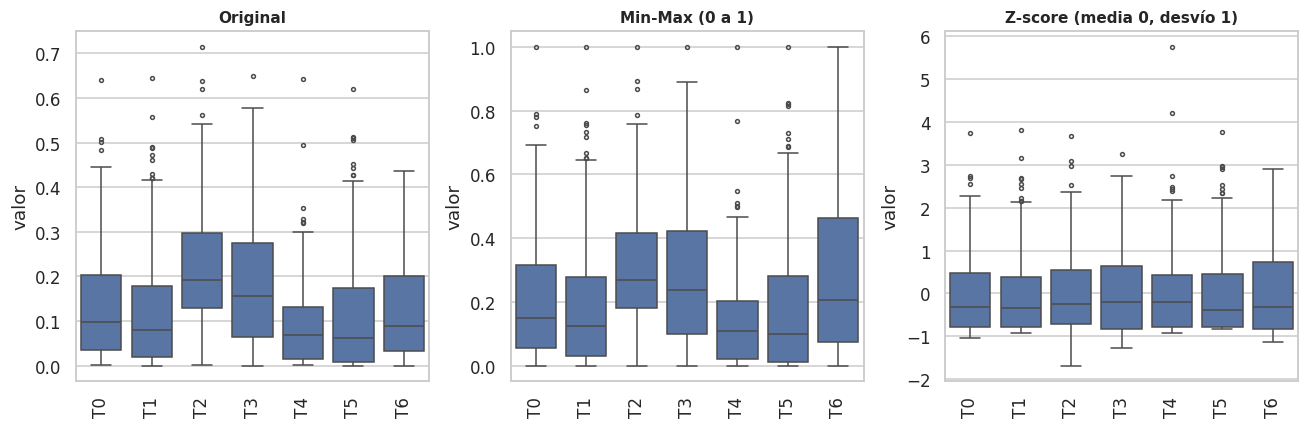

  df NO se modificó: sigue con 171 filas y 8 columnas,
  y sus valores originales (máximo global = 0.7143).


In [35]:
# --- Los escaladores ---
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# OJO: esto es una DEMOSTRACIÓN sobre una copia. No modifica df.
ejemplo = df[predictoras].copy()

mostrar = pd.DataFrame({
    "original_min": ejemplo.min(),
    "original_max": ejemplo.max(),
    "original_media": ejemplo.mean(),
    "original_desvio": ejemplo.std(),
})

minmax_demo = pd.DataFrame(MinMaxScaler().fit_transform(ejemplo),
                           columns=predictoras, index=ejemplo.index)
zscore_demo = pd.DataFrame(StandardScaler().fit_transform(ejemplo),
                           columns=predictoras, index=ejemplo.index)

mostrar["minmax_min"] = minmax_demo.min()
mostrar["minmax_max"] = minmax_demo.max()
mostrar["zscore_media"] = zscore_demo.mean()
mostrar["zscore_desvio"] = zscore_demo.std(ddof=0)

print("=" * 88)
print("  EFECTO DE CADA ESCALADOR")
print("=" * 88)
display(mostrar)
print("  Min-Max deja todo entre 0 y 1.  Z-score deja media 0 y desvío 1.")
print("  Ninguno de los dos cambia la FORMA de la distribución: solo el eje.")

fig, ejes = plt.subplots(1, 3, figsize=(12, 4))
for eje, datos, titulo in zip(
        ejes,
        [ejemplo, minmax_demo, zscore_demo],
        ["Original", "Min-Max (0 a 1)", "Z-score (media 0, desvío 1)"]):
    datos_largos = datos.melt(var_name="variable", value_name="valor")
    sns.boxplot(data=datos_largos, x="variable", y="valor", ax=eje,
                color="#4c72b0", fliersize=2.5)
    eje.set_title(titulo, fontsize=10)
    eje.tick_params(axis="x", rotation=90)
    eje.set_xlabel("")
plt.tight_layout()
plt.show()

print(f"  df NO se modificó: sigue con {df.shape[0]} filas y {df.shape[1]} columnas,")
print(f"  y sus valores originales (máximo global = {df[predictoras].to_numpy().max():.4f}).")

<a id="sec-2-4"></a>
## 2.4 Las matrices X e y

Armamos las dos estructuras que va a consumir el resto del cuaderno:

- **`X`** — la matriz de variables predictoras: una fila por caso, una columna por variable.
- **`y`** — el vector objetivo, ya codificado como 0 y 1.

`X` queda **sin escalar**, a propósito. El escalado se aplica dentro de cada pipeline. El punto
siguiente explica por qué eso no es una preferencia de estilo sino una necesidad.

In [36]:
X = df[predictoras].copy()
# y quedó definido en 2.2

print("=" * 70)
print("  DATOS LISTOS PARA MODELAR")
print("=" * 70)
print(f"  X : {X.shape[0]} filas x {X.shape[1]} columnas  (SIN escalar)")
print(f"  y : {y.shape[0]} etiquetas  ->  "
      f"{int((y == 1).sum())} de clase 1 ({CLASE_POSITIVA}), "
      f"{int((y == 0).sum())} de clase 0 ({clase_negativa})")
print()
print("  Verificaciones finales:")
print(f"    Valores faltantes en X  : {int(X.isna().sum().sum())}")
print(f"    Valores faltantes en y  : {int(y.isna().sum())}")
print(f"    Columnas no numéricas   : {list(X.select_dtypes(exclude=[np.number]).columns)}")
print(f"    Filas alineadas X <-> y : {len(X) == len(y)}")
print()
display(X.head())

  DATOS LISTOS PARA MODELAR
  X : 171 filas x 7 columnas  (SIN escalar)
  y : 171 etiquetas  ->  95 de clase 1 (AFI), 76 de clase 0 (NEG)

  Verificaciones finales:
    Valores faltantes en X  : 0
    Valores faltantes en y  : 0
    Columnas no numéricas   : []
    Filas alineadas X <-> y : True



,T0,T1,T2,T3,T4,T5,T6
0,0.0228,0.2070,0.3818,0.2747,0.0003,0.1131,0.0003
1,0.0068,0.0040,0.0494,0.1765,0.0312,0.4422,0.2899
2,0.1273,0.0005,0.1998,0.3339,0.0259,0.0150,0.2976
3,0.2085,0.1278,0.0905,0.2023,0.1433,0.0004,0.2272
4,0.0004,0.3938,0.1926,0.2707,0.0004,0.0004,0.1416


<a id="sec-2-5"></a>
## 2.5 Reducción de dimensionalidad: PCA

La Parte 2B va a probar, para casi todos los modelos, si conviene aplicarles PCA antes de entrenarlos. Antes de llegar ahí, conviene entender qué hace y por qué, en este dataset puntual, solo tiene sentido comparar dos cantidades de componentes muy puntuales: 6 y 7.

**Qué hace.** El Análisis de Componentes Principales busca un nuevo conjunto de variables —los "componentes principales"— que son combinaciones lineales de las originales, elegidas con una regla fija: el primer componente es la dirección en la que los datos varían más; el segundo es la dirección de mayor varianza que queda, pero obligada a ser perpendicular a la primera (no correlacionada con ella); y así sucesivamente, cada componente nuevo capturando la varianza que
los anteriores dejaron sin explicar. El resultado es una rotación de los ejes originales, ordenada de mayor a menor varianza. "Reducir dimensionalidad" es, entonces, quedarse con los primeros `k` componentes y descartar el resto, con la esperanza de que lo descartado sea mayormente ruido.

**Por qué hay que escalar antes.** PCA elige direcciones de máxima varianza, y la varianza depende de las unidades: una variable medida en una escala más grande domina la cuenta aunque no sea más informativa. Por eso **PCA siempre se aplica sobre datos ya escalados** —acá, estandarizados—; es la misma razón de fondo del punto 2.3, aplicada a una técnica distinta. En la Parte 2B, por eso, PCA siempre va después del escalador dentro del pipeline, nunca antes ni en su lugar.

**Una particularidad de este dataset.** Hay solo siete variables predictoras, así que el máximo
de componentes posibles es siete —el mismo número que las variables originales—. Pedir los siete
retiene el 100 % de la varianza: no se descarta nada. Pero eso **no** significa que "PCA-7" sea lo
mismo que "Sin PCA": PCA-7 sigue siendo una *rotación* de los ejes originales — las variables que
recibe el modelo ya no son los siete tópicos, sino siete combinaciones lineales de ellos, elegidas
para quedar descorrelacionadas entre sí. No se pierde nada de varianza, pero los datos que ve el
modelo son otros.

Si eso cambia el resultado o no depende de qué modelo sea:

*  **SVM, K-Vecinos, Regresión Logística, LDA y QDA** basan sus decisiones en distancias entre
   puntos, en productos internos, o en toda la estructura de covarianza. Una rotación conserva
   exactamente esas distancias y esos productos internos (es, matemáticamente, una isometría), así
   que estos modelos deberían dar, con "Sin PCA" y con "PCA-7", resultados prácticamente
   idénticos: es la misma información geométrica, solo con otro nombre para los ejes.
*  **Árbol de Decisión, Gradient Boosting, AdaBoost y HistGradientBoosting** dividen eje por eje
   ("¿esta variable es mayor que tal valor?"), y esas particiones no son invariantes a rotaciones:
   una frontera que se corta limpio en los ejes originales puede necesitar varios cortes
   zigzagueantes en los ejes rotados de PCA, o al revés. Con estos modelos, "Sin PCA" y "PCA-7"
   pueden dar resultados distintos, aunque no se haya perdido ninguna varianza.
*  **Naive Bayes** asume que las variables son independientes entre sí — y las nuestras no lo son:
   suman 1 en cada fila (punto 2.2), así que están correlacionadas. PCA, además de rotar,
   descorrelaciona: los componentes principales son, por construcción, no correlacionados entre
   sí. Por eso "PCA-7" puede cambiarle el resultado a Naive Bayes, aunque no cambie nada en
   términos de varianza: lo que cambia es qué tan cierto es el supuesto de independencia que el
   modelo necesita.

Dicho eso, el único recorte real de *varianza* posible en este dataset —con un solo componente de
margen— es pedir seis en vez de siete. Por eso la Parte 2B compara justamente "Sin PCA", "PCA-6" y
"PCA-7", y no, por ejemplo, "PCA-2" o "PCA-3", que en un dataset de siete variables serían una
reducción mucho más agresiva.

Hay, además, algo puntual de estas siete variables que ya vimos en el punto 2.2: suman 1 en cada
fila, igual que un one-hot sin `drop_first`. Eso impone una dependencia lineal exacta entre las
siete columnas —la séptima queda determinada apenas se conocen las otras seis—, así que el séptimo
componente de PCA no puede aportar varianza propia: tiene que salir, necesariamente, en cero. En la
práctica, entre "PCA-6" y "PCA-7" la diferencia de varianza retenida debería ser prácticamente
nula — si aparece una diferencia real entre ambas, va a estar en lo que acabamos de ver (si el
modelo es sensible a la rotación o a la correlación), no en cuánta información se conserva.

Lo confirmamos con las variables de este dataset:

  PCA SOBRE LAS 7 VARIABLES  (ya estandarizadas)


,componente,varianza_individual,varianza_acumulada
0,PC1,0.2674,0.2674
1,PC2,0.2085,0.4759
2,PC3,0.1719,0.6478
3,PC4,0.1402,0.7880
4,PC5,0.1122,0.9002
5,PC6,0.0998,1.0000
6,PC7,0.0000,1.0000


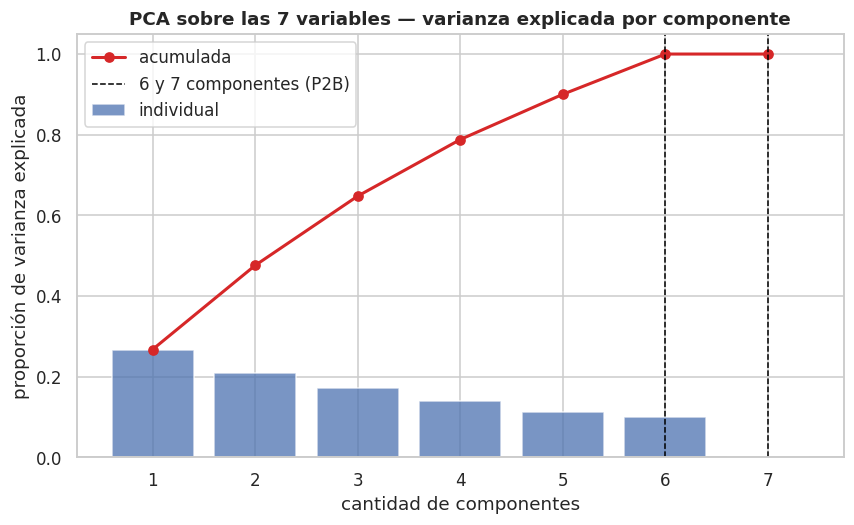

  El 7º componente aporta 0.00% de varianza — prácticamente cero,
  tal como predice la dependencia lineal del punto 2.2.
  Con 6 componentes ya se retiene el 100.00% de la varianza total;
  con 7 (el máximo posible), el 100.00%.


In [37]:
# --- PCA: cuánta varianza explica cada cantidad de componentes ---
from sklearn.decomposition import PCA

demo_entrada = StandardScaler().fit_transform(X)

pca_demo = PCA(random_state=SEMILLA)
pca_demo.fit(demo_entrada)

varianza_individual = pca_demo.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_individual)

tabla_pca = pd.DataFrame({
    "componente": [f"PC{i + 1}" for i in range(len(varianza_individual))],
    "varianza_individual": varianza_individual,
    "varianza_acumulada": varianza_acumulada,
})

print("=" * 78)
print("  PCA SOBRE LAS 7 VARIABLES  (ya estandarizadas)")
print("=" * 78)
display(tabla_pca)

fig, eje = plt.subplots(figsize=(9, 5))
componentes = np.arange(1, len(varianza_individual) + 1)

eje.bar(componentes, varianza_individual, color="#4c72b0", alpha=0.75, label="individual")
eje.plot(componentes, varianza_acumulada, color="#d62728", marker="o", linewidth=2,
         label="acumulada")
eje.axvline(6, color="black", linestyle="--", linewidth=1, label="6 y 7 componentes (P2B)")
eje.axvline(7, color="black", linestyle="--", linewidth=1)

eje.set_xlabel("cantidad de componentes")
eje.set_ylabel("proporción de varianza explicada")
eje.set_xticks(componentes)
eje.set_ylim(0, 1.05)
eje.set_title("PCA sobre las 7 variables — varianza explicada por componente")
eje.legend()
plt.show()

print(f"  El 7º componente aporta {varianza_individual[-1]:.2%} de varianza — prácticamente cero,")
print("  tal como predice la dependencia lineal del punto 2.2.")
print(f"  Con 6 componentes ya se retiene el {varianza_acumulada[5]:.2%} de la varianza total;")
print(f"  con 7 (el máximo posible), el {varianza_acumulada[6]:.2%}.")


---
# 3. División del dataset: entrenamiento y prueba

<a id="sec-3-1"></a>
## 3.1 Por qué hay que dividir

Entrenar un modelo es enseñarle a reconocer patrones. Para saber si **realmente** aprendió, hay que
evaluarlo con datos que no vio durante el entrenamiento.

Si usáramos los mismos datos para las dos cosas, el modelo podría parecer excelente simplemente
porque ya conocía las respuestas. Es como tomarle a alguien un examen con exactamente las mismas
preguntas que estudió: un 10 no prueba que haya entendido el tema, solo que tiene buena memoria.

Por eso la práctica estándar es partir el dataset en dos:

- **Conjunto de entrenamiento** (*training set*) — con el que el modelo ajusta sus parámetros
  internos. Suele ser el 70–80%. Cuantos más datos tenga, mejor puede identificar patrones
  complejos.
- **Conjunto de prueba** (*test set*) — reservado, se usa **una sola vez**, al final, para estimar
  cómo se comportaría el modelo con datos nuevos. Simula el "mundo real": los datos que el modelo
  va a encontrar cuando esté en producción.

Las proporciones habituales son 80/20, 70/30 o 90/10, según el tamaño del dataset. Con pocos datos
conviene dejar más para entrenar; con muchos, se puede ser más generoso con la prueba.

<a id="sec-3-2"></a>
## 3.2 La división 80/20 estratificada

Dos detalles de implementación que importan:

- **`stratify=y`** mantiene la misma proporción de clases en las dos partes. Sin esto, el azar
  podría dejar el conjunto de prueba con muchos más casos de una clase que de la otra, y la
  evaluación quedaría distorsionada. Con clases desbalanceadas es prácticamente obligatorio.
- **`random_state`** fija la aleatoriedad para que la división sea siempre la misma y los
  resultados se puedan reproducir.

In [38]:
# --- Herramienta de división ---
from sklearn.model_selection import train_test_split

X_entrena, X_prueba, y_entrena, y_prueba = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA
)

print("=" * 70)
print("  DIVISIÓN 80 / 20 ESTRATIFICADA")
print("=" * 70)
print(f"  Entrenamiento : {len(X_entrena):>4} casos  ({len(X_entrena)/len(X):.1%})")
print(f"  Prueba        : {len(X_prueba):>4} casos  ({len(X_prueba)/len(X):.1%})")
print()
print("  Reparto de clases (la estratificación lo mantiene parejo):")
print(f"    {'':>16} {CLASE_POSITIVA:>8} {clase_negativa:>8}   % positiva")
for nombre, yy in [("Dataset completo", y), ("Entrenamiento", y_entrena), ("Prueba", y_prueba)]:
    print(f"    {nombre:>16} {int((yy==1).sum()):>8} {int((yy==0).sum()):>8} "
          f"{(yy==1).mean():>11.1%}")
print()
print("  Sin stratify, el conjunto de prueba de 34 casos podría quedar con 25 de")
print("  una clase y 9 de la otra solo por azar, y las métricas serían irreales.")

  DIVISIÓN 80 / 20 ESTRATIFICADA
  Entrenamiento :  136 casos  (79.5%)
  Prueba        :   35 casos  (20.5%)

  Reparto de clases (la estratificación lo mantiene parejo):
                          AFI      NEG   % positiva
    Dataset completo       95       76       55.6%
       Entrenamiento       76       60       55.9%
              Prueba       19       16       54.3%

  Sin stratify, el conjunto de prueba de 34 casos podría quedar con 25 de
  una clase y 9 de la otra solo por azar, y las métricas serían irreales.


<a id="sec-3-3"></a>
## 3.3 La fragilidad de una sola división

Con este dataset, esa división tiene un problema serio que conviene ver antes de seguir.

**34 casos de prueba son muy pocos.** Cada acierto o error mueve el accuracy en casi 3 puntos
porcentuales. Y el resultado depende enteramente de **qué** 34 casos hayan caído del lado de la
prueba, que es cosa del azar.

Lo comprobamos: entrenamos el mismo modelo, con los mismos hiperparámetros, cambiando solamente el
`random_state` de la división. Si la estimación fuera estable, los resultados deberían ser
parecidos.

(Usamos una regresión logística solo como vehículo para la demostración. El modelo en serio,
explicado y evaluado como corresponde, viene en el punto 8 de la Parte 2B.)

  EL MISMO MODELO, 25 DIVISIONES DISTINTAS


,random_state,accuracy,f1_macro
0,0,0.8857,0.8833
1,1,0.9429,0.9428
2,2,0.8571,0.8553
3,3,0.8857,0.8833
4,4,0.9143,0.9140
5,5,0.9714,0.9711
6,6,0.8571,0.8567
7,7,0.7714,0.7667
8,8,0.8857,0.8833
9,9,0.8571,0.8553


  Accuracy mínimo : 0.7714
  Accuracy máximo : 0.9714
  Rango           : 0.2000  (20.0 %)
  Media           : 0.8846
  Desvío          : 0.0544


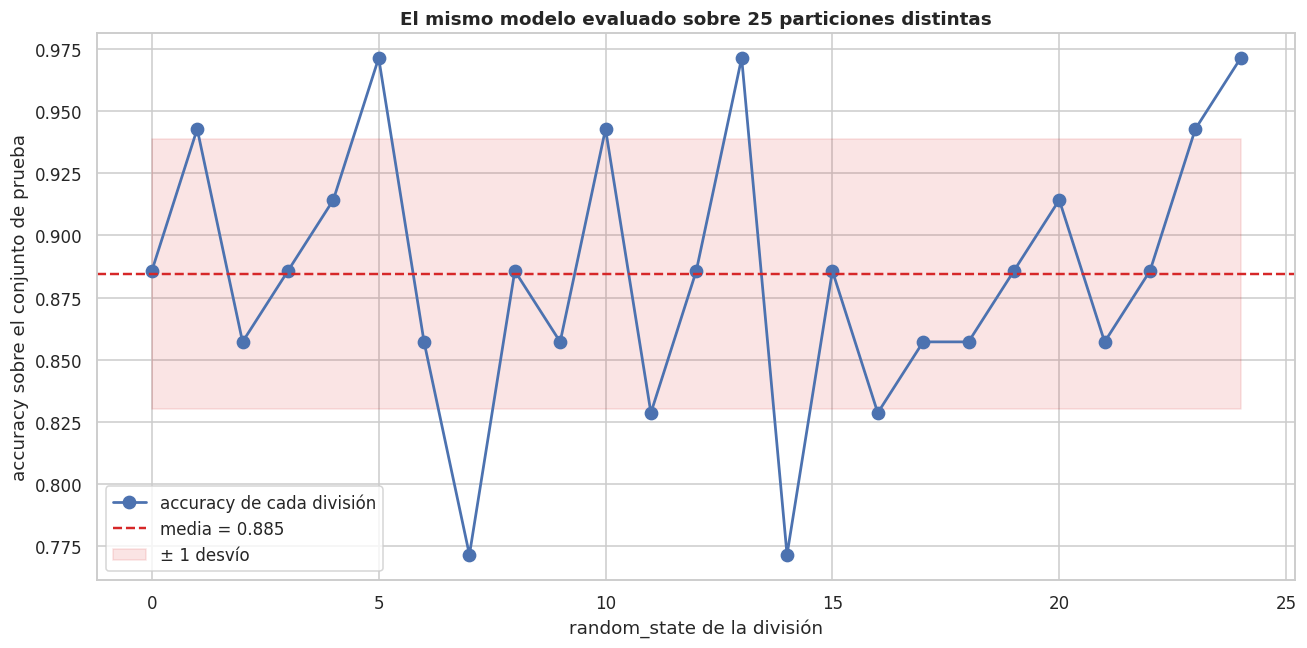

In [39]:
# --- Solo para esta demostración ---
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

modelo_demo = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=5000, random_state=SEMILLA)),
])

N_DIVISIONES = 25   # el único lugar donde se elige cuántas divisiones probar

resultados_particion = []
for semilla in range(N_DIVISIONES):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y,
                                          random_state=semilla)
    modelo_demo.fit(Xtr, ytr)
    predicho = modelo_demo.predict(Xte)
    resultados_particion.append({
        "random_state": semilla,
        "accuracy": accuracy_score(yte, predicho),
        "f1_macro": f1_score(yte, predicho, average="macro"),
    })

resultados_particion = pd.DataFrame(resultados_particion)

print("=" * 70)
print(f"  EL MISMO MODELO, {N_DIVISIONES} DIVISIONES DISTINTAS")
print("=" * 70)
display(resultados_particion)

acc = resultados_particion["accuracy"]
print(f"  Accuracy mínimo : {acc.min():.4f}")
print(f"  Accuracy máximo : {acc.max():.4f}")
print(f"  Rango           : {acc.max() - acc.min():.4f}  "
      f"({(acc.max()-acc.min())*100:.1f} %)")
print(f"  Media           : {acc.mean():.4f}")
print(f"  Desvío          : {acc.std():.4f}")

fig, eje = plt.subplots(figsize=(12, 6))
eje.plot(resultados_particion["random_state"], acc, "o-", color="#4c72b0",
         linewidth=1.8, markersize=8, label="accuracy de cada división")
eje.axhline(acc.mean(), color="#d62728", linestyle="--", linewidth=1.6,
            label=f"media = {acc.mean():.3f}")
eje.fill_between(resultados_particion["random_state"],
                 acc.mean() - acc.std(), acc.mean() + acc.std(),
                 color="#d62728", alpha=0.12, label="± 1 desvío")
eje.set_xlabel("random_state de la división")
eje.set_ylabel("accuracy sobre el conjunto de prueba")
eje.set_title(f"El mismo modelo evaluado sobre {N_DIVISIONES} particiones distintas")
eje.legend()
plt.tight_layout()
plt.show()

CONCLUSIÓN: el mismo modelo, con los mismos datos y los mismos hiperparámetros, arroja resultados muy distintos según cómo se haya partido el dataset. Reportar el número de UNA división sería reportar en buena medida el azar.
Esto es lo que la validación cruzada viene a resolver (punto 6).

---
# 4. Fuga de información (data leakage)

<a id="sec-4-1"></a>
## 4.1 Qué es

**Fuga de información** es cualquier situación en la que el modelo tuvo acceso, directa o
indirectamente, a información del conjunto de prueba durante el entrenamiento.

La palabra clave es **indirectamente**. Nadie copia el conjunto de prueba dentro del de
entrenamiento: eso se vería enseguida. La fuga se da por caminos mucho más sutiles, y el más común
de todos es este:

> Calcular algo usando **todos** los datos, y después dividir.

Un ejemplo concreto: Querér estandarizar las variables. Calculár la media y el desvío de cada columna sobre el dataset completo, aplicár la transformación, y recién entonces dividír en entrenamiento y prueba. Parece razonable —todavía no entrenaste nada—, pero se acaba de filtrar información: esa media y ese desvío contienen los valores del conjunto de prueba. El modelo, al entrenarse sobre datos transformados con esos parámetros, recibe una pista sobre cómo son los datos que después lo van a evaluar.

La regla, en general: **cualquier cosa que se aprenda de los datos tiene que aprenderse solamente del conjunto de entrenamiento.** Medias, desvíos, mínimos, máximos, medianas, listas de variables seleccionadas, categorías conocidas, hiperparámetros. Todo.

<a id="sec-4-2"></a>
## 4.2 Por qué es tan grave: el síntoma es que no hay síntoma

Un error de programación tira una excepción. Un modelo mal configurado da métricas malas. La fuga de información no hace ninguna de las dos cosas: **hace que todo se vea mejor**.

Ese es exactamente el problema. La secuencia típica es así:

1. Se entrena un modelo. Las métricas dan sorprendentemente bien: 96% de accuracy.
2. Nadie sospecha, porque un resultado bueno no se cuestiona con la misma severidad que uno malo.
3. El modelo sale a producción.
4. En producción rinde 78%.
5. Nadie entiende por qué, porque el código "es el mismo".

Y el diagnóstico es difícil justamente porque el código **es** el mismo. La diferencia está en algo que pasó antes.

Tres consecuencias prácticas:

- **La evaluación miente, y miente hacia arriba.** Todas las decisiones que tomes a partir de esas métricas —qué modelo elegir, qué variables conservar, si el proyecto sirve— están basadas en números inflados.
- **La comparación entre modelos se rompe.** _Si un modelo tiene fuga y otro no, el que gana es el que tiene fuga, no el mejor._
- **No hay alarma.** No hay error, no hay aviso, no hay nada que mirar. Solo un número lindo.

Por eso este punto tiene sección propia, y por eso la prevención tiene que ser **estructural** —usar un `Pipeline`— y no depender de acordarse en cada caso.

<a id="sec-4-3"></a>
## 4.3 Las siete formas en que se cuela

Estas son las vías más frecuentes, ordenadas de la más común a la más sutil.

### 1. Escalar antes de dividir

La clásica. `StandardScaler().fit_transform(X)` sobre el dataset completo y después
`train_test_split`. La media y el desvío que usa la transformación contienen los datos de prueba.

**Cómo se evita:** `fit_transform` sobre el entrenamiento, `transform` sobre la prueba. O, mejor,
**poner el escalador adentro de un `Pipeline`.**

### 2. Imputar valores faltantes antes de dividir

Idéntico al anterior. Si imputás con la mediana de todo el dataset, esa mediana incluye las filas de prueba.

**Cómo se evita:** `SimpleImputer` dentro del `Pipeline`.

### 3. Seleccionar variables mirando todo el dataset

Calculás la correlación de cada variable con la etiqueta usando las 171 filas, te quedás con las 10 mejores, y recién después dividís. Esa selección ya vio las etiquetas de prueba. Es la fuga **más peligrosa de todas**, porque puede inventar señal donde no hay ninguna —lo demostramos en 4.5—.

**Cómo se evita:** `SelectKBest` dentro del `Pipeline`, o cualquier selección hecha solo con el conjunto de entrenamiento.

### 4. Ajustar hiperparámetros contra el conjunto de prueba

Probás `max_depth` de 1 a 15, mirás cuál da mejor accuracy **en el conjunto de prueba** y te
quedás con ese. El conjunto de prueba dejó de ser independiente: lo usaste para decidir. El número que reportás ya no es una estimación honesta.

**Cómo se evita:** tres conjuntos (entrenamiento, validación, prueba), o validación cruzada anidada: un bucle interno que elige los hiperparámetros y uno externo que evalúa.

### 5. Duplicados repartidos entre las dos partes

Si la misma fila aparece dos veces y una copia cae en entrenamiento y la otra en prueba, el modelo "acierta" ese caso porque lo memorizó. Con muchos duplicados, la evaluación se infla mucho. Esta es la razón de fondo del control de duplicados de la Parte 1.

**Cómo se evita:** eliminar duplicados **antes** de dividir. Y si hay grupos naturales —varias filas del mismo cliente, del mismo paciente, del mismo documento— hay que dividir por grupo, no por fila: `GroupKFold`.

### 6. Variables que no existirían en el momento de predecir

Una columna que se llena *después* de que ocurre lo que querés predecir. El ejemplo clásico:
predecir si un paciente tiene una enfermedad usando como variable "medicación recetada". La medicación se receta *porque* ya se diagnosticó. En producción esa columna estaría vacía.

Es el tipo de fuga que ningún `Pipeline` previene: hace falta entender de dónde sale cada dato y cuándo se registra.

**Cómo se evita:** preguntar, para cada variable, *¿esto lo voy a tener en el momento en que necesite predecir?*

### 7. Datos con orden temporal partidos al azar

Si las filas tienen fecha y partís al azar, el modelo entrena con datos de marzo y se evalúa con datos de enero: está prediciendo el pasado con información del futuro. En producción eso nunca pasa.

**Cómo se evita:** división temporal —entrenar con lo viejo, evaluar con lo nuevo— y `TimeSeriesSplit` en lugar de `KFold`.

---

**En nuestro dataset**, las formas 5, 6 y 7 no aplican: no hay duplicados (lo verificamos en la Parte 1), las siete variables se calculan todas juntas en el mismo momento, y no hay orden temporal. Las que sí nos afectan son la **1** (el escalado), la **3** (la selección de variables) y la **4** (el ajuste de `k` y de la poda del árbol). Las dos primeras las prevenimos con el `Pipeline`; sobre la tercera vamos a ser honestos en las limitaciones del punto 12.8 de la Parte 2B.

<a id="sec-4-4"></a>
## 4.4 Ejemplo: El escalador que mira de más

Empecemos por la más simple: cuánto cambian los parámetros del escalador según se los calcule con todo el dataset o solo con el entrenamiento.

Esta demostración muestra el **mecanismo**. Las diferencias en los
parámetros son chicas, pero son datos del conjunto de prueba que se están filtrando, y el efecto crece cuanto más chico es el dataset y más extremos tiene.

In [40]:
# --- MAL: el escalador ve todo el dataset, incluido el conjunto de prueba ---
escalador_mal = StandardScaler().fit(X)

# --- BIEN: el escalador solo ve el conjunto de entrenamiento ---
escalador_bien = StandardScaler().fit(X_entrena)

comparacion = pd.DataFrame({
    "media_con_todo_MAL": escalador_mal.mean_,
    "media_solo_entrena_BIEN": escalador_bien.mean_,
    "dif_medias": escalador_mal.mean_ - escalador_bien.mean_,
    "desvio_con_todo_MAL": np.sqrt(escalador_mal.var_),
    "desvio_solo_entrena_BIEN": np.sqrt(escalador_bien.var_),
}, index=predictoras)
comparacion["dif_desvios"] = (comparacion["desvio_con_todo_MAL"] -
                              comparacion["desvio_solo_entrena_BIEN"])

print("=" * 88)
print("  LOS PARÁMETROS DEL ESCALADOR CAMBIAN SEGÚN QUÉ DATOS VIO")
print("=" * 88)
display(comparacion)

print("  Esas diferencias son información del conjunto de prueba filtrándose")
print("  hacia la transformación que se aplica al entrenamiento.")
print()
print(f"  Diferencia relativa máxima en las medias : "
      f"{(comparacion['dif_medias'].abs() / comparacion['media_solo_entrena_BIEN'].abs()).max():.2%}")
print(f"  Diferencia relativa máxima en los desvíos: "
      f"{(comparacion['dif_desvios'].abs() / comparacion['desvio_solo_entrena_BIEN']).max():.2%}")
print()
print("  Con Min-Max el efecto es más visible todavía, porque el mínimo y el máximo")
print("  dependen de UN SOLO valor cada uno: si el valor más alto del dataset está")
print("  en el conjunto de prueba, el escalador 'sabe' hasta dónde llegan los datos")
print("  que todavía no vio.")

minmax_todo = MinMaxScaler().fit(X)
minmax_entrena = MinMaxScaler().fit(X_entrena)
comparacion_mm = pd.DataFrame({
    "max_con_todo_MAL": minmax_todo.data_max_,
    "max_solo_entrena_BIEN": minmax_entrena.data_max_,
    "diferencia": minmax_todo.data_max_ - minmax_entrena.data_max_,
}, index=predictoras)
print()
display(comparacion_mm)
cuantas = int((comparacion_mm["diferencia"].abs() > 1e-12).sum())
print(f"  En {cuantas} de {len(predictoras)} variables, el valor máximo del dataset")
print("  está en el conjunto de PRUEBA. Escalando con todo, el modelo lo 'sabe'.")

  LOS PARÁMETROS DEL ESCALADOR CAMBIAN SEGÚN QUÉ DATOS VIO


,media_con_todo_MAL,media_solo_entrena_BIEN,dif_medias,desvio_con_todo_MAL,desvio_solo_entrena_BIEN,dif_desvios
T0,0.1401,0.1436,-0.0035,0.1340,0.1364,-0.0024
T1,0.1261,0.1321,-0.0061,0.1358,0.1400,-0.0042
T2,0.2249,0.2133,0.0116,0.1332,0.1196,0.0136
T3,0.1840,0.1870,-0.0030,0.1434,0.1458,-0.0024
T4,0.0892,0.0937,-0.0045,0.0963,0.1021,-0.0058
T5,0.1122,0.1078,0.0043,0.1348,0.1293,0.0055
T6,0.1235,0.1224,0.0011,0.1079,0.1087,-0.0009


  Esas diferencias son información del conjunto de prueba filtrándose
  hacia la transformación que se aplica al entrenamiento.

  Diferencia relativa máxima en las medias : 5.46%
  Diferencia relativa máxima en los desvíos: 11.41%

  Con Min-Max el efecto es más visible todavía, porque el mínimo y el máximo
  dependen de UN SOLO valor cada uno: si el valor más alto del dataset está
  en el conjunto de prueba, el escalador 'sabe' hasta dónde llegan los datos
  que todavía no vio.



,max_con_todo_MAL,max_solo_entrena_BIEN,diferencia
T0,0.6410,0.6410,0.0000
T1,0.6447,0.6447,0.0000
T2,0.7143,0.6205,0.0938
T3,0.6492,0.6492,0.0000
T4,0.6432,0.6432,0.0000
T5,0.6206,0.5124,0.1082
T6,0.4358,0.4358,0.0000


  En 2 de 7 variables, el valor máximo del dataset
  está en el conjunto de PRUEBA. Escalando con todo, el modelo lo 'sabe'.


<a id="sec-4-5"></a>
## 4.5 El Pipeline como antídoto

La conclusión práctica de todo esto: **no hay que confiar en acordarse**. La prevención tiene que
ser estructural.

Un **`Pipeline`** de scikit-learn encadena una serie de pasos —transformaciones y, al final, un
modelo— y los trata como un único objeto. Lo importante es cómo se comporta:

- Cuando se le pide `fit`, aplica `fit_transform` a cada transformación **con los datos que
  recibe**.
- Cuando se le pide `predict`, aplica solamente `transform`, con los parámetros que aprendió en el
  `fit`.

Y acá está la clave: cuando un `Pipeline` se pasa a una función de validación cruzada, **ese ciclo
se repite dentro de cada pliegue**. El escalador se reajusta cinco veces, cada una con el 80% de
entrenamiento de ese pliegue, y se aplica al 20% restante sin haberlo visto nunca.

La fuga deja de ser un error posible y pasa a ser imposible.

```python
# En lugar de esto, que es frágil:
X_escalado = StandardScaler().fit_transform(X)      # <-- vio todo
modelo.fit(X_escalado, y)

# Esto, que es a prueba de descuidos:
pipeline = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo",    LogisticRegression()),
])
cross_val_score(pipeline, X, y, cv=cv)              # <-- reajusta en cada pliegue
```
La secuencia sería así:

```
PLIEGUE i
├── separar train y test
├── tomar SOLO train
├── StandardScaler aprende media/desvío del train
├── transforma el train
├── LogisticRegression aprende con ese train escalado
└── guardamos acceso al escalador para inspeccionarlo
```

Todo el resto de la Parte 2 usa pipelines. La función `construir_pipeline()` del punto 7.2 de la Parte 2B es la que los arma, y ningún modelo se evalúa fuera de uno.

<a id="sec-4-5"></a>
## 4.6 Lista de control

Para aplicar antes de dar por buena cualquier evaluación:

| # | Pregunta | Si la respuesta es "no" |
|---|---|---|
| 1 | ¿El escalado está adentro de un `Pipeline`? | Moverlo adentro |
| 2 | ¿La imputación está adentro del `Pipeline`? | Moverla adentro |
| 3 | ¿La selección de variables está adentro del `Pipeline`? | Moverla adentro |
| 4 | ¿Los duplicados se eliminaron **antes** de dividir? | Eliminarlos y volver a dividir |
| 5 | ¿Hay grupos naturales (cliente, paciente, documento) repartidos entre las partes? | Usar `GroupKFold` |
| 6 | ¿Cada variable va a existir en el momento de predecir? | Sacar las que no |
| 7 | ¿Los datos tienen orden temporal? | Dividir por tiempo, `TimeSeriesSplit` |
| 8 | ¿Los hiperparámetros se eligieron mirando el conjunto de prueba? | Validación cruzada anidada |
| 9 | ¿El resultado es sospechosamente bueno? | Buscar la fuga antes de festejar |

Un resultado muy por encima de lo esperable es, estadísticamente, más
veces una fuga que un hallazgo.

---
# 5. Overfitting y underfitting

Este es, junto con la fuga de información, el concepto que más decide si un modelo sirve o no.
La diferencia entre los dos es importante: la fuga es un **error de procedimiento** —se comete o
no se comete, y se evita con un `Pipeline`—, mientras que el ajuste es un **equilibrio** que hay
que buscar de nuevo en cada problema. No existe el modelo que esté bien ajustado por defecto.

Este punto es todo conceptual hasta el 5.7. Recién ahí aparece el código, y lo que hace es mostrar
en nuestros datos lo que acá se explica en general.

<a id="sec-5-1"></a>
## 5.1 Qué es cada uno

Todo modelo tiene que encontrar un equilibrio entre dos errores opuestos: **aprender de menos y
aprender de más.**

Conviene tener presente cuál es el objetivo real. No queremos un modelo que acierte los casos que
ya tenemos —esos ya vienen con la respuesta escrita al lado—. Queremos uno que acierte **casos que
todavía no existen**. A eso se le llama **generalizar**, y es la única medida de éxito que
importa.

### Overfitting (sobreajuste)

El modelo aprende **demasiado bien** los datos de entrenamiento. En lugar de captar los patrones generales, memoriza los detalles: el ruido, los casos particulares, los errores de carga, las casualidades de esa muestra concreta.

A simple vista parece un éxito: las predicciones sobre los datos conocidos son casi perfectas. El problema aparece con datos nuevos, donde el modelo falla, porque los detalles que memorizó no se repiten.

**Cuándo aparece:** cuando el modelo es demasiado complejo para la cantidad de datos disponibles.
Un árbol sin límite de profundidad, un KNN con *k*=1, un bosque enorme sobre 50 filas, una red neuronal con más parámetros que ejemplos. La palabra clave es **para la cantidad de datos**: el mismo árbol que sobreajusta con 171 filas puede estar perfectamente ajustado con 100.000.


### Underfitting (subajuste)

El caso opuesto. El modelo **no logra captar los patrones** ni siquiera en los datos de entrenamiento. Se equivoca en todos lados por igual.

**Cuándo aparece:** cuando el modelo es demasiado simple para el problema —una recta para separar datos que forman círculos concéntricos—, cuando las variables no representan bien el fenómeno, o cuando se entrenó con muy pocas iteraciones.

**Por qué es menos peligroso:** porque se nota. Un modelo que rinde mal en todos lados no engaña a nadie: el primer número que uno mira ya avisa. El sobreajuste, en cambio, se disfraza de éxito.

Que sea menos peligroso no quiere decir que sea aceptable. Un modelo subajustado es un modelo que no sirve, solo que además lo dice de entrada.

### El equilibrio

Entre los dos extremos hay una zona donde el modelo aprende lo suficiente para generalizar sin memorizar. Encontrarla es uno de los objetivos centrales de todo el proceso.


![Equilibrio entre subajuste y sobreajuste](https://raw.githubusercontent.com/FerCipriani/CursoML_Proyecto_IVE/0725680b93281348bfc5ea0b7b11e5591a6742c1/Ajuste.png)


Hay tres cosas para leer en ese gráfico:

El error de entrenamiento baja siempre que se agrega complejidad. Nunca sube. Por eso, por sí solo, no informa nada: un modelo con error de entrenamiento cero puede ser excelente o puede ser una tabla de búsqueda.
El error de validación baja y después sube. Ese cambio de dirección es el único indicador confiable, y el punto donde ocurre es el objetivo.
La distancia vertical entre las dos curvas —la brecha— se ensancha hacia la derecha. Esa distancia es lo que vamos a medir.

<a id="sec-5-2"></a>
## 5.2 El compromiso sesgo–varianza

Sobreajuste y subajuste son la cara visible de algo más general, que conviene conocer porque
explica *por qué* no se pueden evitar los dos a la vez.

El error que un modelo comete con datos nuevos se descompone en tres partes:

```
error esperado  =  sesgo²  +  varianza  +  error irreducible
```

**Sesgo (*bias*)** — cuánto se equivoca el modelo **sistemáticamente**, por ser demasiado simple
para la forma real del problema. Un modelo con mucho sesgo se equivoca siempre para el mismo lado,
sin importar con qué datos lo entrenemos. Es el subajuste visto desde adentro.

**Varianza** — cuánto **cambia el modelo** si lo entrenamos con otra muestra del mismo fenómeno.
Un modelo con mucha varianza es inestable: entrenado con estas 171 filas da una cosa, entrenado
con otras 171 igual de válidas da algo bastante distinto. Es el sobreajuste visto desde adentro.

**Error irreducible** — el ruido propio del fenómeno. Dos casos con exactamente las mismas
variables de entrada pueden tener etiquetas distintas, sencillamente porque las variables no
contienen toda la información que determina el resultado. Ningún modelo puede bajar de ahí. Si el
error irreducible de un problema es del 15 %, un modelo que reporta 98 % de accuracy no es
brillante: es sospechoso.

### La analogía del tiro al blanco

Es la que mejor fija la idea. Cada entrenamiento con una muestra distinta es un tiro:

|  | **Poca varianza** | **Mucha varianza** |
|---|---|---|
| **Poco sesgo** | Los tiros agrupados en el centro. Es el objetivo | Los tiros repartidos alrededor del centro: en promedio dan bien, pero cualquiera de ellos por separado puede estar lejos |
| **Mucho sesgo** | Los tiros agrupados, pero lejos del centro. Consistentemente equivocado | Los tiros repartidos **y** desviados. El peor de los casos |

Notá que "en promedio da bien" no consuela: en la práctica entrenamos el modelo **una sola vez**,
con los datos que tenemos. Un modelo de alta varianza es una apuesta.

### Por qué es un compromiso y no un problema con solución

Bajar el sesgo —darle más capacidad al modelo— **sube** la varianza. Bajar la varianza
—limitarlo— **sube** el sesgo. Moviendo la complejidad no se pueden minimizar los dos a la vez:
por eso se habla de un *compromiso* (*trade-off*).

Lo que sí se puede hacer es bajar los dos cambiando **otra cosa**:

| Qué cambiar | Efecto | Por qué |
|---|---|---|
| **Más datos** | Baja la varianza, no toca el sesgo | Con más ejemplos, las casualidades pesan menos y el modelo entrenado con una muestra se parece más al entrenado con otra |
| **Mejores variables** | Baja el sesgo, no toca la varianza | Si la información está mejor representada, un modelo simple alcanza. Es lo que hace valioso al feature engineering |
| **Conjuntos (*ensembles*)** | Bajan la varianza | Promediar muchos modelos de alta varianza cancela buena parte de sus errores individuales. Es exactamente la razón de ser del Random Forest del punto 11 de la Parte 2B |
| **Regularización** | Baja la varianza a cambio de algo de sesgo | Es un movimiento sobre el compromiso, no una salida de él, pero suele ser un buen negocio |

### Dónde se para cada uno de estos cuatro modelos

| Modelo | Sesgo | Varianza | Comentario |
|---|---|---|---|
| Regresión Logística | Alto | Baja | Solo puede dibujar un plano; la regularización L2 le baja todavía más la varianza |
| KNN con *k* grande | Alto | Baja | Promedia sobre muchos vecinos: se vuelve casi una constante |
| KNN con *k* = 1 | Muy bajo | Muy alta | Cada predicción depende de un único caso |
| Árbol sin podar | Muy bajo | Muy alta | Puede separar cada caso en su propia hoja |
| Árbol podado | Medio | Media | La poda es exactamente el mando de este compromiso |
| Random Forest | Bajo | Baja | Conserva el bajo sesgo del árbol y le cancela la varianza promediando |

Esa última fila explica por qué el Random Forest suele ganar: es el único de los cuatro que consigue mejorar en las dos columnas a la vez, y lo logra porque no cambia la complejidad del modelo individual sino la cantidad de modelos. El precio que paga es que deja de ser legible.

<a id="sec-5-3"></a>
## 5.3 Las señales: tabla de diagnóstico

La forma básica de diagnosticar es comparar el rendimiento del modelo **en los datos con los que
entrenó** contra el de **datos que no vio**. Los cuatro escenarios posibles:

| Rendimiento en entrenamiento | Rendimiento en validación | Diagnóstico | Qué está pasando | Qué hacer |
|---|---|---|---|---|
| Alto (0,99) | Bajo (0,72) | **Sobreajuste** | Memorizó | Simplificar el modelo o conseguir más datos |
| Bajo (0,65) | Bajo (0,63) | **Subajuste** | No aprendió | Dar más capacidad o mejores variables |
| Alto (0,92) | Alto (0,89) | **Correcto** | Generaliza | Nada: es el objetivo |
| Bajo (0,70) | Alto (0,85) | **Raro** | Casi siempre indica un error en el código, o una regularización que solo se aplica al entrenar | Revisar el código antes que el modelo |

Sobre la cuarta fila, que desconcierta cuando aparece: rendir **mejor** en datos que no se vieron
que en los de entrenamiento no es una buena noticia, es un síntoma. Las causas habituales son que
el conjunto de validación quedó más fácil por azar —muy común con pocos datos—, que hay filas
repetidas entre las dos partes, o que el modelo aplica una penalización o un *dropout* durante el
entrenamiento que después desactiva.


### Otras señales, menos obvias

**El modelo tiene muchos más parámetros que datos.** Un árbol con 150 hojas sobre 171 filas está prácticamente guardando una fila por hoja. La regla de bolsillo: si la cantidad de decisiones que el modelo puede tomar se acerca a la cantidad de ejemplos que vio, no está aprendiendo, está indexando.

**Los resultados cambian mucho al cambiar la semilla.** Un modelo que generaliza da resultados
parecidos con cualquier partición. Uno que memoriza depende de qué le haya tocado memorizar. Es exactamente lo que medimos en 3.3.

**El desvío entre pliegues es grande.** Si el F1 va de 0,70 a 0,95 según el pliegue, el modelo no está capturando algo estable: está reaccionando a los datos puntuales de cada partición.

**El modelo usa variables que no tienen sentido.** Si al mirar la importancia de las variables aparece arriba una que no debería importar, puede estar explotando una casualidad de la muestra.
Este es el único indicio que exige conocer el dominio, y por eso es tan valioso: ninguna métrica lo detecta.

**Las probabilidades son extremas.** Un modelo que predice 0,999 y 0,001 y casi nada en el medio suele estar demasiado seguro de sí mismo. Las métricas de calibración —*log loss* y *Brier*, que calculamos en el punto 7.3 de la Parte 2B— son sensibles a esto, mientras que el accuracy no lo nota.

### Tres cosas que parecen sobreajuste y no lo son

| Lo que se ve | Por qué no es sobreajuste |
|---|---|
| El modelo acierta el 100 % en entrenamiento | Por sí solo no dice nada. Si también acierta en validación, el problema simplemente era fácil |
| Hay una brecha de 0,04 | Con un conjunto de validación chico, una brecha de ese tamaño puede ser enteramente ruido de medición. Hay que compararla contra el desvío entre pliegues |
| El rendimiento cae al pasar a producción | Puede ser sobreajuste, pero también *data drift*: los datos nuevos ya no se parecen a los viejos. Son problemas distintos con soluciones distintas |

<a id="sec-5-4"></a>
## 5.4 Las cuatro formas de detectarlo

### Forma 1 — La brecha entre entrenamiento y validación

La más directa. Se entrena el modelo, se lo evalúa **sobre los mismos datos de entrenamiento** y
sobre datos que no vio, y se comparan los dos números.

*Cómo se lee:* la resta. Cuanto más grande, más memoriza.

*Qué la hace útil:* es inmediata y no requiere nada especial. Debería ser el primer número que uno
mira de cualquier modelo.

*Su límite:* con una sola partición, la medición es ruidosa. Como vimos en 3.3, el resultado sobre
25 casos de prueba se mueve varios puntos según el azar. Una brecha de 0,05 puede ser sobreajuste
o puede ser la partición que le tocó.

### Forma 2 — La curva de validación

Se repite el entrenamiento variando **un hiperparámetro que controla la complejidad** —la
profundidad del árbol, el *k* de KNN, la fuerza de la regularización— y se grafican las dos
curvas: rendimiento en entrenamiento y en validación, contra complejidad.

*Cómo se lee:*

- La curva de entrenamiento **sube siempre**: más complejidad, más capacidad de memorizar.
- La de validación sube hasta un punto y después **baja**.
- El punto donde las dos se separan marca el comienzo del sobreajuste.
- El máximo de la curva de validación marca la complejidad justa.
- Si las dos curvas están bajas y juntas en toda la izquierda del gráfico, eso es subajuste.

*Qué la hace útil:* no dice solo "hay sobreajuste", dice **dónde empieza** y **cuánta complejidad
conviene**. Es una herramienta de diagnóstico y de ajuste a la vez.

*Su límite:* mira un hiperparámetro por vez. Si la complejidad está repartida entre varios —la
profundidad *y* el mínimo de casos por hoja, por ejemplo—, la curva de uno solo puede engañar. Ahí
conviene una búsqueda en grilla, que es lo que usamos con el árbol en el punto 10 de la Parte 2B.

### Forma 3 — El desvío entre pliegues de la validación cruzada

En lugar de una partición, se usan cinco o diez, y se mira no solo la media sino la **dispersión**
de los resultados.

*Cómo se lee:* un desvío chico significa que el modelo rinde parecido sin importar qué datos le
toquen —está capturando algo estable—. Un desvío grande significa que el rendimiento depende de la
partición, que es otra forma de decir que el modelo está reaccionando a particularidades de los
datos y no a un patrón general.

*Qué la hace útil:* es la única de las cuatro que da una **medida del error de la medición**. Sin
ella no se puede saber si la diferencia entre dos modelos es real. Es la que vamos a usar en toda la comparativa del punto 12 de la Parte 2B.

*Su límite:* no distingue entre un modelo inestable y un dataset chico. Con 171 filas, cierto
desvío es inevitable venga el modelo que venga.

### Forma 4 — La curva de aprendizaje

Grafica el rendimiento contra la **cantidad de datos** en lugar de contra la complejidad. Se entrena el mismo modelo con el 20 %, el 30 %, el 40 %… de los datos disponibles, y en cada tamaño se miden las dos curvas.

Responde una pregunta distinta de las anteriores, y muy práctica: ***¿conviene conseguir más datos?***

*Cómo se lee:*

- Si las dos curvas **convergen y se aplanan** en un valor bajo, más datos no van a ayudar: el   problema es el modelo. Hay **sesgo alto** y lo que hace falta es un modelo más expresivo o mejores variables.
- Si las dos curvas **siguen separadas** y la de validación todavía viene subiendo en el extremo derecho, más datos sí ayudarían. Hay **varianza alta**.
- Si la curva de entrenamiento arranca en 1,0 y se mantiene ahí, el modelo memoriza desde el primer momento.

*Qué la hace útil:* es la única que informa sobre una decisión que está **fuera del modelo** —ir a buscar más datos, que suele ser lo más caro del proyecto— y la única que distingue con claridad un problema de sesgo de uno de varianza.

*Su límite:* es la más cara de calcular, porque entrena el modelo muchas veces sobre muchos tamaños.

### Las cuatro, resumidas

| Forma | Contra qué grafica | Qué pregunta responde | Costo |
|---|---|---|---|
| Brecha | nada, es un número | ¿Hay sobreajuste? | Nulo |
| Curva de validación | complejidad | ¿Cuánta complejidad conviene? | Medio |
| Desvío entre pliegues | nada, es un número | ¿Cuánto vale esta medición? | Bajo |
| Curva de aprendizaje | cantidad de datos | ¿Conviene conseguir más datos? | Alto |

Las cuatro se usan en este cuaderno: la 1 y la 2 en los puntos 5.7 y 5.8, la 4 en el 5.9, y la 3
en todo el resto, desde el punto 6 hasta el final.

<a id="sec-5-5"></a>
## 5.5 Cómo se mide: la brecha y sus umbrales

La **brecha** es la medida más usada:

```
brecha = rendimiento en entrenamiento - rendimiento en validación
```

Cuanto más grande, más memoriza el modelo. Pero *cuánto* es mucho no tiene una respuesta
universal: depende del tamaño del dataset, del problema y de qué métrica se use.

Algunas referencias prácticas, que son convenciones y no leyes:

| Brecha (en F1 o accuracy) | Lectura habitual |
|---|---|
| Menor a 0,02 | Sin señales de sobreajuste |
| 0,02 a 0,05 | Normal, sobre todo en datasets chicos |
| 0,05 a 0,10 | Aviso: conviene no aumentar más la complejidad |
| Mayor a 0,10 | Sobreajuste que hay que atender |
| Mayor a 0,20 | El modelo está memorizando |

Y tres cosas que la brecha sola no dice:

**El nivel.** Una brecha de 0,01 con un F1 de 0,60 en validación no es un buen modelo: es un
modelo que aprende poco y de manera consistente. Por eso hay que mirar **brecha y nivel juntos**.

**El error de medición.** Una brecha de 0,04 medida sobre 34 casos no es distinguible de una de
0,00. Con pocos datos, la brecha hay que estimarla con validación cruzada y compararla contra el
desvío entre pliegues. Si la brecha es menor que el desvío, no está demostrada.

**Con qué métrica se calculó.** La brecha en accuracy y la brecha en F1 macro del mismo modelo
pueden ser bastante distintas, sobre todo si las clases están desbalanceadas. Hay que decir
siempre con cuál se midió. En este cuaderno usamos **F1 macro**, porque trata a las dos clases por
igual.

En este cuaderno los umbrales están declarados en la siguiente celda de código:

```python
BRECHA_SOBREAJUSTE = 0.10   # por encima: se avisa sobreajuste
DESVIO_INESTABLE   = 0.08   # por encima: se avisa inestabilidad
SCORE_SUBAJUSTE    = 0.70   # por debajo: se avisa subajuste
```

Y la función `diagnosticar_ajuste()` del punto 7.3 de la Parte 2B los aplica automáticamente a cada modelo. Están
arriba de todo, con nombre, justamente para que se puedan discutir y cambiar en lugar de quedar
escondidos en el medio del código. Si te parecen mal calibrados para este problema, cambiarlos es
una línea y todo el cuaderno se recalcula.

In [41]:
# --- Umbrales del diagnóstico de ajuste ---
BRECHA_SOBREAJUSTE = 0.10   # (score entrenamiento - score validación) por encima de esto
DESVIO_INESTABLE   = 0.08   # desvío entre pliegues por encima de esto
SCORE_SUBAJUSTE    = 0.70   # score de validación por debajo de esto

<a id="sec-5-6"></a>
## 5.6 Qué hacer con cada uno

Los dos problemas tienen remedios **opuestos**. Por eso diagnosticar bien es la mitad del trabajo:
aplicar el remedio equivocado empeora las cosas. Bajarle la profundidad a un árbol que ya estaba
subajustado lo empeora dos veces.

### Contra el subajuste: darle más capacidad al modelo

| Remedio | En concreto | Cuándo es el correcto |
|---|---|---|
| Usar un modelo más expresivo | Pasar de una regresión logística a un árbol o un bosque | Cuando la frontera real no es lineal |
| Aumentar la complejidad | Subir `max_depth`, bajar `k` en KNN, subir `C` (menos regularización) | Cuando el modelo elegido está frenado por sus hiperparámetros |
| Mejorar las variables | Feature engineering: crear variables que representen mejor el fenómeno | Cuando hay información latente que el modelo no puede deducir solo |
| Entrenar más | Más iteraciones, más árboles | Cuando el entrenamiento se cortó antes de converger |
| Revisar la limpieza | A veces el problema es que se eliminó información valiosa al "limpiar" | Cuando el rendimiento empeoró justo después de limpiar |

### Contra el sobreajuste: limitar al modelo o darle más datos

| Remedio | En concreto | Cuándo es el correcto |
|---|---|---|
| Simplificar el modelo | Bajar `max_depth`, subir `min_samples_leaf`, subir `k` en KNN | Casi siempre, y es lo primero que conviene probar |
| Regularizar | Penalizar los coeficientes grandes: bajar `C` en la regresión logística | En modelos lineales y en redes |
| Conseguir más datos | El remedio más eficaz de todos, y casi siempre el menos disponible | Cuando la curva de aprendizaje (5.4, forma 4) muestra que todavía sube |
| Reducir variables | Menos columnas, menos oportunidades de encontrar casualidades | Cuando hay muchas más variables que filas |
| Usar conjuntos (*ensembles*) | Un bosque promedia muchos árboles y cancela buena parte del sobreajuste individual | Cuando el modelo base es bueno pero inestable |
| Parada temprana | En modelos iterativos, cortar cuando el error de validación deja de bajar | En *boosting* y redes neuronales |
| Validar bien | La validación cruzada no evita el sobreajuste, pero lo hace visible | Siempre |

### Dónde se sobreajusta cada uno de estos modelos

Esta tabla es el puente entre este punto y los puntos 8 a 11 de la Parte 2B: dice, para cada modelo, cuál es el
mando que controla su complejidad y hacia qué lado hay que moverlo.

| Modelo | El mando | Sobreajusta cuando | Subajusta cuando | Valor por defecto en scikit-learn |
|---|---|---|---|---|
| **Regresión Logística** | `C` (inverso de la regularización) | `C` muy alto, o hay más variables que filas | `C` muy bajo | `C=1.0`, regularización L2 moderada. Sobreajusta poco de fábrica |
| **KNN** | `n_neighbors` (*k*) | *k* = 1: cada predicción depende de un solo vecino | *k* comparable al tamaño del dataset | `k=5`. Es el modelo donde el mando se ve más claro |
| **Árbol de Decisión** | `max_depth` y `min_samples_leaf` | Sin límite de profundidad: puede aislar cada caso en su hoja | Profundidad 1 o 2 | **Sin límites**: sobreajusta por defecto. Hay que podarlo a mano |
| **Random Forest** | `n_estimators`, `max_features`, `max_depth` | Rara vez, y nunca por agregar árboles | Profundidad muy limitada | Sin límite de profundidad, pero el promedio lo compensa |

Dos observaciones que vale la pena retener:

- **El árbol es el único que sobreajusta por defecto.** Un `DecisionTreeClassifier()` recién
  sacado de la caja crece hasta separar cada caso. Por eso en el punto 10 de la Parte 2B buscamos la poda con una
  grilla, mientras que a la logística no le tocamos nada.
- **En el Random Forest, agregar árboles nunca empeora.** Más árboles es siempre mejor o igual, y
  solo cuesta tiempo. Es la excepción a la regla de que más complejidad trae sobreajuste, y la
  razón es que los árboles no se suman: se promedian.

### Un caso particular: la regularización

Vale detenerse porque es el remedio más usado y el menos intuitivo. Regularizar es agregarle a la
función que el modelo minimiza un término que **penaliza la complejidad**. El modelo deja de
buscar solamente el mejor ajuste y pasa a buscar un equilibrio entre ajustar bien y mantenerse
simple.

En términos del punto 5.2: la regularización **compra varianza barata a cambio de sesgo caro**.
Empeora un poco el ajuste sobre los datos que ya tenemos, a cambio de que el modelo no cambie
tanto con datos nuevos. En datasets chicos ese intercambio casi siempre conviene.

Las dos formas habituales:

| Penalización | Qué penaliza | Efecto característico |
|---|---|---|
| **L2** (*Ridge*) | La suma de los coeficientes **al cuadrado** | Achica todos los coeficientes de manera pareja; ninguno llega a cero |
| **L1** (*Lasso*) | La suma de los **valores absolutos** | Lleva algunos coeficientes exactamente a cero: selecciona variables sola |

En la regresión logística se controla con el parámetro `C`, que es el **inverso** de la fuerza de
la penalización: valores chicos regularizan **más** —coeficientes más chicos, modelo más simple— y
valores grandes regularizan menos. Es una convención que confunde a todo el mundo la primera vez.

Por defecto scikit-learn usa `C=1.0` con penalización L2, que es una regularización moderada y
**siempre activa**. Es, entre otras cosas, lo que hace que la regresión logística funcione bien en
datasets chicos sin necesidad de ajustar nada.

<a id="sec-5-7"></a>
## 5.7 En código: tres niveles de complejidad

Con los conceptos claros, vamos a verlos en nuestros datos.

Tomamos el mismo modelo —un árbol de decisión— en tres niveles de complejidad: uno **sin límite de
profundidad**, que puede memorizar cada caso; uno de **profundidad 3**; y uno de **profundidad 1**,
que solo puede hacer una pregunta. Los tres se entrenan con los mismos datos y se evalúan sobre el
entrenamiento y sobre la prueba.

Esta es la **forma 1** de 5.4: la brecha. Lo que esperamos ver, si todo lo anterior es cierto:

- El árbol sin límite debería acertar **todo** en entrenamiento y bastante menos en prueba.
- El de profundidad 3 debería quedar en el medio, con una brecha chica.
- El de profundidad 1 debería tener una brecha mínima pero un nivel bajo —subajuste—.

La columna `hojas` de la tabla es la que hace visible el mecanismo: dice en cuántos grupos terminó
partiendo el árbol los datos de entrenamiento.

  TRES NIVELES DE COMPLEJIDAD


,modelo,hojas,profundidad,accuracy_entrenamiento,accuracy_prueba,brecha
0,Árbol sin límite (complejo),13,6,1.0000,0.8000,0.2000
1,Árbol de profundidad 3 (medio),8,3,0.9485,0.7714,0.1771
2,Árbol de profundidad 1 (simple),2,1,0.8309,0.7143,0.1166


  Árbol sin límite (complejo)        -> brecha 0.200: SOBREAJUSTE  |  nivel 0.800: aceptable
  Árbol de profundidad 3 (medio)     -> brecha 0.177: SOBREAJUSTE  |  nivel 0.771: aceptable
  Árbol de profundidad 1 (simple)    -> brecha 0.117: SOBREAJUSTE  |  nivel 0.714: aceptable

  Notá la columna 'hojas': el árbol sin límite llegó a 13 hojas
  para 136 casos de entrenamiento, es decir unos 10.5 casos por hoja,
  y con eso alcanza para acertarlos TODOS (accuracy de entrenamiento = 1,000).
  Eso es memorizar, no aprender.

  ADVERTENCIA IMPORTANTE sobre estos números:
  el accuracy de prueba está medido sobre 35 casos. Cada acierto
  o error vale 2.9 puntos, así que las tres brechas de esta tabla
  tienen un margen de error grande. Sirven para ver el PATRÓN —más
  complejidad, más brecha— pero no para decidir nada con precisión.
  En el punto 6 vamos a volver a medirlo como corresponde.


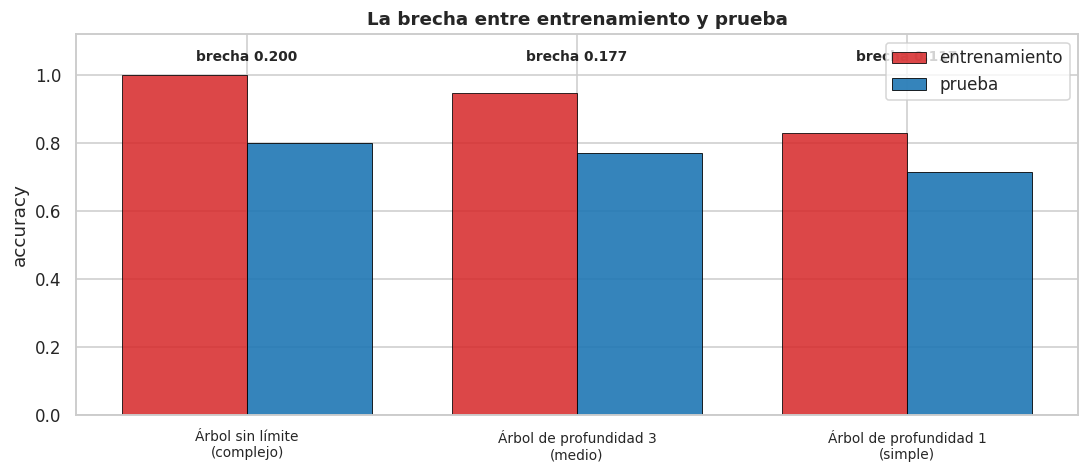

In [42]:
from sklearn.tree import DecisionTreeClassifier

ejemplos = {
    "Árbol sin límite (complejo)":     DecisionTreeClassifier(random_state=SEMILLA),
    "Árbol de profundidad 3 (medio)":  DecisionTreeClassifier(max_depth=3, random_state=SEMILLA),
    "Árbol de profundidad 1 (simple)": DecisionTreeClassifier(max_depth=1, random_state=SEMILLA),
}

comparacion_ajuste = []
for nombre, estimador in ejemplos.items():
    estimador.fit(X_entrena, y_entrena)
    acc_tr = accuracy_score(y_entrena, estimador.predict(X_entrena))
    acc_te = accuracy_score(y_prueba, estimador.predict(X_prueba))
    comparacion_ajuste.append({
        "modelo": nombre,
        "hojas": estimador.get_n_leaves(),
        "profundidad": estimador.get_depth(),
        "accuracy_entrenamiento": acc_tr,
        "accuracy_prueba": acc_te,
        "brecha": acc_tr - acc_te,
    })

comparacion_ajuste = pd.DataFrame(comparacion_ajuste)

print("=" * 96)
print("  TRES NIVELES DE COMPLEJIDAD")
print("=" * 96)
display(comparacion_ajuste)

for _, fila in comparacion_ajuste.iterrows():
    partes = []
    if fila["brecha"] > BRECHA_SOBREAJUSTE:
        partes.append(f"brecha {fila['brecha']:.3f}: SOBREAJUSTE")
    elif fila["brecha"] > BRECHA_SOBREAJUSTE / 2:
        partes.append(f"brecha {fila['brecha']:.3f}: sobreajuste leve")
    else:
        partes.append(f"brecha {fila['brecha']:.3f}: aceptable")
    if fila["accuracy_prueba"] < SCORE_SUBAJUSTE:
        partes.append(f"nivel {fila['accuracy_prueba']:.3f}: bajo, señal de SUBAJUSTE")
    else:
        partes.append(f"nivel {fila['accuracy_prueba']:.3f}: aceptable")
    print(f"  {fila['modelo']:<34} -> {'  |  '.join(partes)}")

print()
casos_por_hoja = len(X_entrena) / comparacion_ajuste.loc[0, "hojas"]
print(f"  Notá la columna 'hojas': el árbol sin límite llegó a "
      f"{comparacion_ajuste.loc[0, 'hojas']} hojas")
print(f"  para {len(X_entrena)} casos de entrenamiento, es decir unos "
      f"{casos_por_hoja:.1f} casos por hoja,")
print("  y con eso alcanza para acertarlos TODOS (accuracy de entrenamiento = 1,000).")
print("  Eso es memorizar, no aprender.")
print()
print("  ADVERTENCIA IMPORTANTE sobre estos números:")
print(f"  el accuracy de prueba está medido sobre {len(X_prueba)} casos. Cada acierto")
print(f"  o error vale {100/len(X_prueba):.1f} puntos, así que las tres brechas de esta tabla")
print("  tienen un margen de error grande. Sirven para ver el PATRÓN —más")
print("  complejidad, más brecha— pero no para decidir nada con precisión.")
print("  En el punto 6 vamos a volver a medirlo como corresponde.")

fig, eje = plt.subplots(figsize=(10, 4.4))
posiciones = np.arange(len(comparacion_ajuste))
ancho = 0.38
eje.bar(posiciones - ancho/2, comparacion_ajuste["accuracy_entrenamiento"], ancho,
        label="entrenamiento", color="#d62728", alpha=0.85, edgecolor="black", linewidth=0.6)
eje.bar(posiciones + ancho/2, comparacion_ajuste["accuracy_prueba"], ancho,
        label="prueba", color="#1f77b4", alpha=0.9, edgecolor="black", linewidth=0.6)
eje.set_xticks(posiciones)
eje.set_xticklabels([m.replace(" (", "\n(") for m in comparacion_ajuste["modelo"]], fontsize=9)
eje.set_ylabel("accuracy")
eje.set_ylim(0, 1.12)
eje.set_title("La brecha entre entrenamiento y prueba")
eje.legend()
for i, fila in comparacion_ajuste.iterrows():
    eje.text(i, 1.04, f"brecha {fila['brecha']:.3f}", ha="center", fontsize=9,
             fontweight="bold")
plt.tight_layout()
plt.show()

<a id="sec-5-8"></a>
## 5.8 La curva de validación

Ahora la **forma 2** de 5.4. Repetimos el experimento anterior variando la profundidad del árbol
de 1 a 15 y graficamos las dos curvas, para ver el recorrido completo en lugar de tres puntos
sueltos.

Acá la hacemos con la división simple 80/20, que es lo único que tenemos hasta este punto del
cuaderno. Sale muy temblorosa la curva de prueba: sube y baja de manera errática. Eso **no** es el comportamiento del modelo, es el ruido de estar midiendo sobre 34 casos.

En el punto 6.4 vamos a repetir exactamente este gráfico con validación cruzada, y la diferencia va a ser evidente. Es la mejor justificación de por qué hace falta.

  CURVA DE VALIDACIÓN con una sola división 80/20


,max_depth,entrenamiento,prueba,brecha
0,1,0.8250,0.7024,0.1226
1,2,0.9094,0.7667,0.1427
2,3,0.9470,0.7667,0.1803
3,4,0.9850,0.7697,0.2153
4,5,0.9925,0.7420,0.2505
5,6,1.0000,0.7974,0.2026
6,7,1.0000,0.7974,0.2026
7,8,1.0000,0.7974,0.2026
8,9,1.0000,0.7974,0.2026
9,10,1.0000,0.7974,0.2026


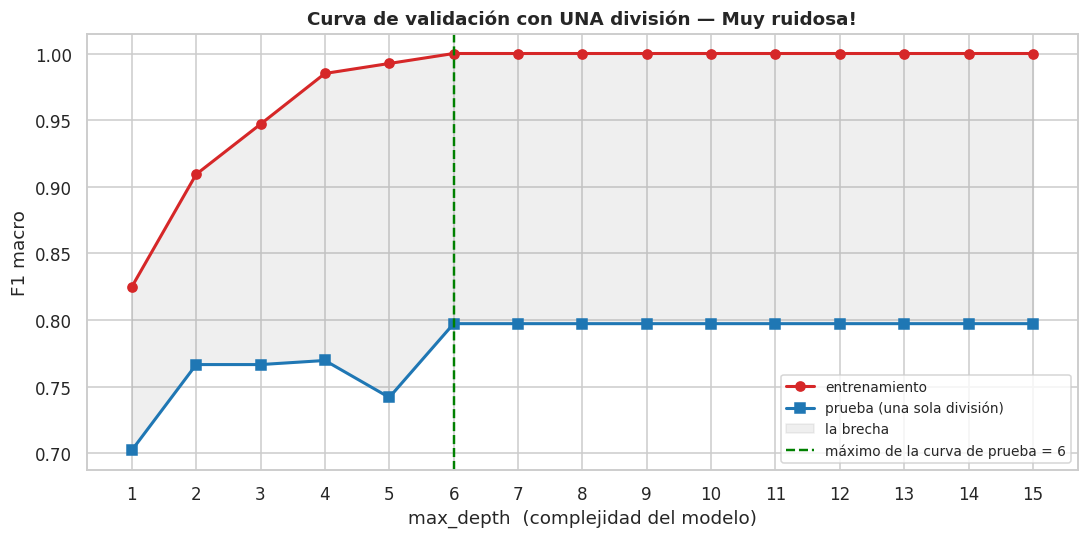

  Qué se ve:
    - La curva roja (entrenamiento) sube siempre hasta llegar a 1,0 y quedarse.
      Más profundidad = más capacidad de memorizar.
    - La curva azul (prueba) sube, baja, vuelve a subir. Ese zigzag NO es el
      modelo: es el ruido de medir sobre 34 casos.
    - El área gris es la brecha, que se ensancha hacia la derecha.

  Con esta curva, ¿cuál es la profundidad óptima? El máximo está en 6,
  pero con tanto ruido es difícil confiar en ese número. Lo repetimos en 6.4
  con validación cruzada.


In [43]:
profundidades = list(range(1, 16))
curva_simple = []

for prof in profundidades:
    arbol = DecisionTreeClassifier(max_depth=prof, random_state=SEMILLA)
    arbol.fit(X_entrena, y_entrena)
    curva_simple.append({
        "max_depth": prof,
        "entrenamiento": f1_score(y_entrena, arbol.predict(X_entrena), average="macro"),
        "prueba": f1_score(y_prueba, arbol.predict(X_prueba), average="macro"),
    })

curva_simple = pd.DataFrame(curva_simple)
curva_simple["brecha"] = curva_simple["entrenamiento"] - curva_simple["prueba"]

print("=" * 78)
print("  CURVA DE VALIDACIÓN con una sola división 80/20")
print("=" * 78)
display(curva_simple)

fig, eje = plt.subplots(figsize=(10, 5))
eje.plot(curva_simple["max_depth"], curva_simple["entrenamiento"], "o-",
         color="#d62728", linewidth=2, label="entrenamiento")
eje.plot(curva_simple["max_depth"], curva_simple["prueba"], "s-",
         color="#1f77b4", linewidth=2, label="prueba (una sola división)")
eje.fill_between(curva_simple["max_depth"], curva_simple["prueba"],
                 curva_simple["entrenamiento"], color="grey", alpha=0.12,
                 label="la brecha")
mejor_simple = int(curva_simple.loc[curva_simple["prueba"].idxmax(), "max_depth"])
eje.axvline(mejor_simple, color="green", linestyle="--", linewidth=1.6,
            label=f"máximo de la curva de prueba = {mejor_simple}")
eje.set_xlabel("max_depth  (complejidad del modelo)")
eje.set_ylabel("F1 macro")
eje.set_title("Curva de validación con UNA división — Muy ruidosa!")
eje.set_xticks(profundidades)
eje.legend(fontsize=9)
plt.tight_layout()
plt.show()

print("  Qué se ve:")
print("    - La curva roja (entrenamiento) sube siempre hasta llegar a 1,0 y quedarse.")
print("      Más profundidad = más capacidad de memorizar.")
print("    - La curva azul (prueba) sube, baja, vuelve a subir. Ese zigzag NO es el")
print("      modelo: es el ruido de medir sobre 34 casos.")
print("    - El área gris es la brecha, que se ensancha hacia la derecha.")
print()
print(f"  Con esta curva, ¿cuál es la profundidad óptima? El máximo está en {mejor_simple},")
print("  pero con tanto ruido es difícil confiar en ese número. Lo repetimos en 6.4")
print("  con validación cruzada.")

---
# 6. Validación cruzada K-Fold

<a id="sec-6-1"></a>
## 6.1 Cómo funciona

El punto 3.3 mostró el problema: la evaluación depende de cómo se partió el dataset. El punto 5
mostró qué buscamos detectar. La **validación cruzada** resuelve las dos cosas.

En lugar de partir el dataset una sola vez, se lo divide en *K* partes llamadas **pliegues**
(*folds*). Después se entrena *K* veces: en cada vuelta, un pliegue distinto hace de conjunto de
prueba y los otros *K-1* de entrenamiento.

```
   Pliegue 1:  [PRUEBA][entrena][entrena][entrena][entrena]
   Pliegue 2:  [entrena][PRUEBA][entrena][entrena][entrena]
   Pliegue 3:  [entrena][entrena][PRUEBA][entrena][entrena]
   Pliegue 4:  [entrena][entrena][entrena][PRUEBA][entrena]
   Pliegue 5:  [entrena][entrena][entrena][entrena][PRUEBA]
```

El esquema dibujado usa cinco pliegues para que entre en la página; el valor real lo fija
`N_PLIEGUES` en el punto 0.4.

Así **cada caso del dataset es evaluado exactamente una vez**, por un modelo que no lo vio durante
su entrenamiento. Al final se tienen *K* mediciones: su **media** es la estimación del rendimiento,
y su **desvío** dice cuán confiable es esa estimación.

<a id="sec-6-2"></a>
## 6.2 Cuántos pliegues, y por qué acá no es opcional

Tres razones concretas, no genéricas:

**1. El dataset es chico.** Con 171 filas, un conjunto de prueba del 20% son 34 casos. Ya vimos en
3.3 que la estimación se mueve varios puntos de un `random_state` a otro, y en 5.8 que la curva de
validación sale ilegible de tan ruidosa. La validación cruzada usa las 171 filas para evaluar, no
34.

**2. Vamos a comparar varios modelos y tres escalados.** Muchas combinaciones. Si las diferencias
entre ellas son de unos pocos puntos y la medición tiene un ruido del mismo orden, la comparación
no significa nada. La validación cruzada da, además de la media, el **desvío entre pliegues**, que
es lo que permite decir si una diferencia observada es real o cabe dentro del ruido. Sin esa
segunda cifra, un ranking de modelos es una lista de casualidades ordenadas.

**3. No se desperdicia ningún dato.** Cada caso participa del entrenamiento en *K-1* vueltas y de
la evaluación en una. Con 171 filas, reservar 34 y no usarlas nunca para entrenar es un lujo que no
nos podemos dar.

**Estratificada, además.** Usamos `StratifiedKFold`, que arma los pliegues manteniendo en cada uno
la misma proporción de clases que el dataset completo. Sin estratificar, algún pliegue podría
quedar con un reparto muy distinto y su métrica sería poco representativa.

### Cuántos pliegues

**La cantidad de pliegues es un solo parámetro: `N_PLIEGUES`, en el punto 0.4.** De ahí lo toma todo
el cuaderno —el objeto `cv`, las demostraciones de los puntos 4 y 5, los encabezados de las tablas y
los títulos de los gráficos—. No hay ningún `5` ni ningún `10` escrito en otra celda, así que
cambiarlo ahí arriba cambia el cuaderno entero, y la Parte 2B lo declara igual en su propio 0.3.

Con 171 filas las dos opciones razonables son:

| K | Entrena por vuelta | Evalúa por pliegue | A favor | En contra |
|---|---|---|---|---|
| **5** | ~137 casos (80 %) | ~34 casos | La mitad de tiempo de cómputo, y cada medición individual se hace sobre una muestra más grande, así que el desvío entre pliegues es más estable | Estimación levemente más pesimista: el modelo entrena con menos datos de los que en realidad tiene disponibles |
| **10** | ~154 casos (90 %) | ~17 casos | Estimación menos sesgada, porque cada modelo entrena con casi todo el dataset | Más varianza entre pliegues —17 casos por medición— y el doble de ajustes que hacer |

Lo que **no** cambia entre las dos es cuántos datos se usan: en los dos casos las 171 filas se
evalúan exactamente una vez. Lo que cambia es en cuántos pedazos se reparte esa evaluación, y por lo
tanto cuánto ruido tiene cada pedazo. El valor con el que viene configurado este cuaderno lo imprime
la celda del punto 0.4, y la celda de 6.3 lo muestra pliegue por pliegue.

¿Y el extremo, K = número de filas (*leave-one-out*)? Cada pliegue evalúa sobre un solo caso. Es
insesgado pero extremadamente ruidoso y 171 veces más caro.

<a id="sec-6-3"></a>
## 6.3 El esquema estratificado

In [44]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=SEMILLA)

print("=" * 78)
print(f"  ESQUEMA DE VALIDACIÓN: StratifiedKFold con {N_PLIEGUES} pliegues")
print("=" * 78)
print(f"  {'Pliegue':>8} {'Entrena':>9} {'Prueba':>8} {'% pos. entrena':>16} {'% pos. prueba':>15}")
for i, (idx_tr, idx_te) in enumerate(cv.split(X, y), start=1):
    print(f"  {i:>8} {len(idx_tr):>9} {len(idx_te):>8} "
          f"{y.iloc[idx_tr].mean():>15.1%} {y.iloc[idx_te].mean():>15.1%}")
print()
print(f"  Proporción de la clase positiva en el dataset completo: {y.mean():.1%}")
print("  La estratificación la mantiene casi idéntica en todos los pliegues.")

  ESQUEMA DE VALIDACIÓN: StratifiedKFold con 10 pliegues
   Pliegue   Entrena   Prueba   % pos. entrena   % pos. prueba
         1       153       18           55.6%           55.6%
         2       154       17           55.2%           58.8%
         3       154       17           55.2%           58.8%
         4       154       17           55.2%           58.8%
         5       154       17           55.2%           58.8%
         6       154       17           55.8%           52.9%
         7       154       17           55.8%           52.9%
         8       154       17           55.8%           52.9%
         9       154       17           55.8%           52.9%
        10       154       17           55.8%           52.9%

  Proporción de la clase positiva en el dataset completo: 55.6%
  La estratificación la mantiene casi idéntica en todos los pliegues.


<a id="sec-6-4"></a>
## 6.4 Una división contra validación cruzada

Dos comparaciones que cierran el argumento.

**La primera:** el mismo modelo evaluado de las dos formas.

In [45]:
modelo_demo.fit(X_entrena, y_entrena)
una_division = f1_score(y_prueba, modelo_demo.predict(X_prueba), average="macro")

resultado_cv = cross_validate(modelo_demo, X, y, cv=cv, scoring="f1_macro",
                              return_train_score=True)
por_pliegue = resultado_cv["test_score"]

print("=" * 78)
print("  UNA DIVISIÓN vs. VALIDACIÓN CRUZADA   (F1 macro)")
print("=" * 78)
print(f"  Una sola división 80/20 : {una_division:.4f}   <- un número solo, sin idea del error")
print()
print("  Validación cruzada, pliegue por pliegue:")
for i, s in enumerate(por_pliegue, start=1):
    print(f"      pliegue {i} : {s:.4f}")
print()
print(f"  Media                   : {por_pliegue.mean():.4f}")
print(f"  Desvío entre pliegues   : {por_pliegue.std():.4f}")
print(f"  Rango                   : {por_pliegue.min():.4f} a {por_pliegue.max():.4f}")
print()
print(f"  ESTIMACIÓN FINAL: {por_pliegue.mean():.4f} ± {por_pliegue.std():.4f}")
print()
print("  Esa segunda cifra es la que permite decir si una diferencia entre dos")
print("  modelos es real o si entra dentro del ruido de la medición.")
print("  De acá en adelante, TODA evaluación del cuaderno se hace así.")

  UNA DIVISIÓN vs. VALIDACIÓN CRUZADA   (F1 macro)
  Una sola división 80/20 : 0.8250   <- un número solo, sin idea del error

  Validación cruzada, pliegue por pliegue:
      pliegue 1 : 0.8889
      pliegue 2 : 0.7984
      pliegue 3 : 0.8132
      pliegue 4 : 0.8235
      pliegue 5 : 0.9377
      pliegue 6 : 0.8786
      pliegue 7 : 0.9412
      pliegue 8 : 0.9404
      pliegue 9 : 0.9412
      pliegue 10 : 1.0000

  Media                   : 0.8963
  Desvío entre pliegues   : 0.0637
  Rango                   : 0.7984 a 1.0000

  ESTIMACIÓN FINAL: 0.8963 ± 0.0637

  Esa segunda cifra es la que permite decir si una diferencia entre dos
  modelos es real o si entra dentro del ruido de la medición.
  De acá en adelante, TODA evaluación del cuaderno se hace así.


**La segunda:** la curva de validación de 5.8, rehecha con validación cruzada.

Es el mismo gráfico, el mismo modelo y el mismo rango de profundidades. Lo único que cambia es cómo
se mide cada punto: antes, con una sola división de 34 casos; ahora, con el promedio de los pliegues, y con una banda que muestra el desvío entre ellos.

Compará las dos curvas azules. La de 5.8 zigzaguea y su máximo es prácticamente arbitrario. Esta
tiene una forma clara: sube, llega a un máximo, y baja. Y la banda sombreada dice, en cada punto,
cuánta confianza merece ese valor.

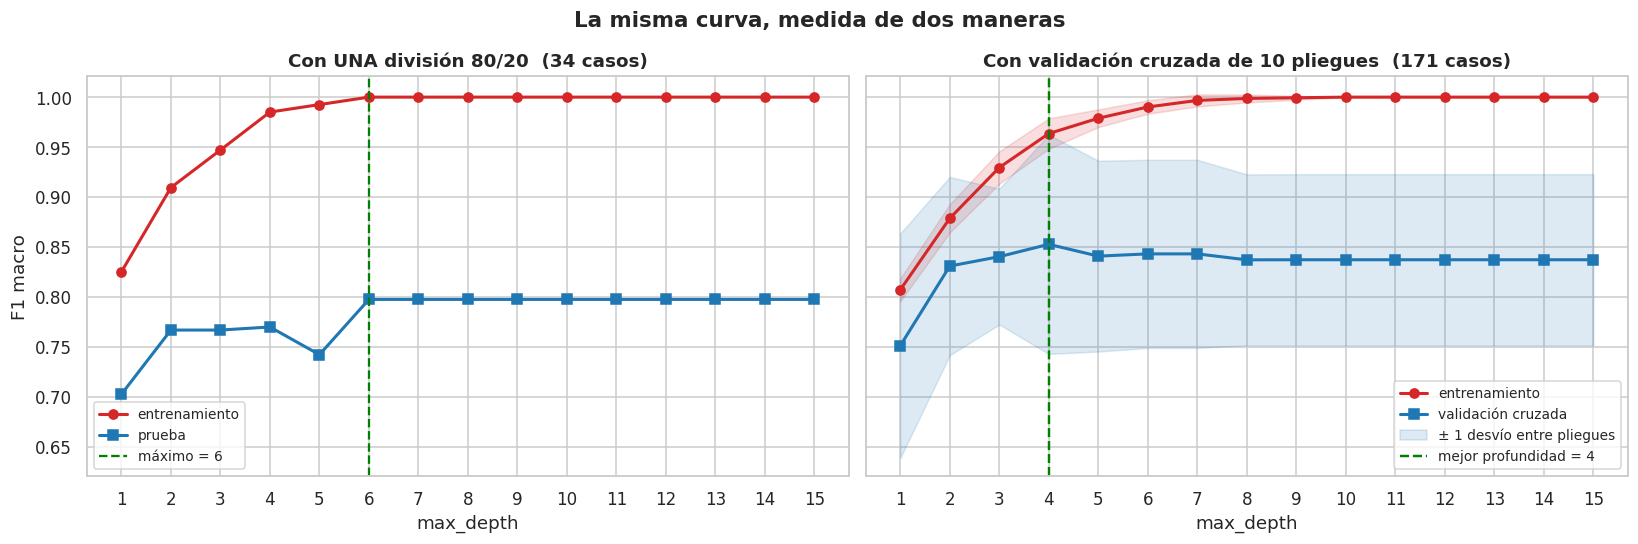

  LECTURA DE LA CURVA CON VALIDACIÓN CRUZADA
  Zona de SUBAJUSTE   : max_depth de 1 a 3
  Mejor complejidad   : max_depth = 4  (F1 macro = 0.8526 ± 0.1098)
  Zona de SOBREAJUSTE : max_depth mayor a 4

  Brecha en el óptimo : 0.1109
  Brecha en el extremo: 0.1629  (max_depth = 15)

  La curva de una sola división daba como óptimo max_depth = 6;
  la validación cruzada da 4. La segunda merece mucha más confianza:
  está promediando 10 mediciones en lugar de reportar una.

  Y la banda sombreada agrega algo que la curva de la izquierda no tenía:
  una medida de cuánta confianza merece cada punto.


In [46]:
from sklearn.model_selection import validation_curve

scores_tr, scores_val = validation_curve(
    DecisionTreeClassifier(random_state=SEMILLA),
    X, y,
    param_name="max_depth",
    param_range=profundidades,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1,
)

media_tr, desvio_tr = scores_tr.mean(axis=1), scores_tr.std(axis=1)
media_val, desvio_val = scores_val.mean(axis=1), scores_val.std(axis=1)
mejor = int(np.argmax(media_val))
mejor_profundidad = profundidades[mejor]

fig, ejes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# Izquierda: la de 5.8, con una sola división
ejes[0].plot(curva_simple["max_depth"], curva_simple["entrenamiento"], "o-",
             color="#d62728", linewidth=2, label="entrenamiento")
ejes[0].plot(curva_simple["max_depth"], curva_simple["prueba"], "s-",
             color="#1f77b4", linewidth=2, label="prueba")
ejes[0].axvline(mejor_simple, color="green", linestyle="--", linewidth=1.5,
                label=f"máximo = {mejor_simple}")
ejes[0].set_title("Con UNA división 80/20  (34 casos)")
ejes[0].set_xlabel("max_depth"); ejes[0].set_ylabel("F1 macro")
ejes[0].set_xticks(profundidades)
ejes[0].legend(fontsize=9)

# Derecha: con validación cruzada
ejes[1].plot(profundidades, media_tr, "o-", color="#d62728", linewidth=2,
             label="entrenamiento")
ejes[1].fill_between(profundidades, media_tr - desvio_tr, media_tr + desvio_tr,
                     color="#d62728", alpha=0.15)
ejes[1].plot(profundidades, media_val, "s-", color="#1f77b4", linewidth=2,
             label="validación cruzada")
ejes[1].fill_between(profundidades, media_val - desvio_val, media_val + desvio_val,
                     color="#1f77b4", alpha=0.15, label="± 1 desvío entre pliegues")
ejes[1].axvline(mejor_profundidad, color="green", linestyle="--", linewidth=1.6,
                label=f"mejor profundidad = {mejor_profundidad}")
ejes[1].set_title(f"Con validación cruzada de {N_PLIEGUES} pliegues  (171 casos)")
ejes[1].set_xlabel("max_depth")
ejes[1].set_xticks(profundidades)
ejes[1].legend(fontsize=9)

fig.suptitle("La misma curva, medida de dos maneras", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("=" * 78)
print("  LECTURA DE LA CURVA CON VALIDACIÓN CRUZADA")
print("=" * 78)
print(f"  Zona de SUBAJUSTE   : max_depth de 1 a {max(1, mejor_profundidad - 1)}")
print(f"  Mejor complejidad   : max_depth = {mejor_profundidad}  "
      f"(F1 macro = {media_val[mejor]:.4f} ± {desvio_val[mejor]:.4f})")
print(f"  Zona de SOBREAJUSTE : max_depth mayor a {mejor_profundidad}")
print()
print(f"  Brecha en el óptimo : {media_tr[mejor] - media_val[mejor]:.4f}")
print(f"  Brecha en el extremo: {media_tr[-1] - media_val[-1]:.4f}  (max_depth = {profundidades[-1]})")
print()
print(f"  La curva de una sola división daba como óptimo max_depth = {mejor_simple};")
print(f"  la validación cruzada da {mejor_profundidad}. La segunda merece mucha más confianza:")
print(f"  está promediando {N_PLIEGUES} mediciones en lugar de reportar una.")
print()
print("  Y la banda sombreada agrega algo que la curva de la izquierda no tenía:")
print("  una medida de cuánta confianza merece cada punto.")

---
<a id="sec-export"></a>
# Exportar el estado para la Parte 2B

<a id="sec-export-1"></a>
## Qué deja este cuaderno

Este cuaderno termina acá y la Parte 2B sigue con los modelos. Entre los dos hay un archivo: la
Parte 2B no vuelve a tocar el dataset limpio, parte directamente de lo que exporta esta celda.

**Qué se le hizo realmente a los datos.** Menos de lo que parece:

| Punto | Qué se hizo | ¿Modificó los datos? |
|---|---|---|
| 0.3 | Verificación de la entrada | No |
| 2.1 | Variables derivadas: construidas, medidas y descartadas | No |
| 2.2 | **Codificación de la etiqueta a 0 y 1** | **Sí** |
| 2.3 | Normalización y estandarización | No: se demostraron sobre una copia |
| 2.4 | Armado de las matrices `X` e `y` | Reorganiza, no transforma |
| 3 a 6 | Divisiones, fugas, curvas, pliegues | No: todo sobre copias |

El único cambio real es la codificación de la etiqueta. El escalado no se aplica acá a propósito:
depende del modelo, y en la Parte 2B va adentro de un `Pipeline` que lo reajusta en cada pliegue
(punto 4.6); guardar los datos sin escalar deja esa decisión abierta.

El archivo que se exporta, `datos_modelado.csv`, lleva la etiqueta **dos veces**: `TAG` con el
texto original y `y` con el 0/1. Con `y` sola alcanzaría para entrenar, pero conservar las dos
permite que la Parte 2B **verifique** que su clase positiva configurada coincide con la
codificación del archivo, en vez de darlo por sentado.

No hace falta un archivo de configuración aparte: la lista de predictoras no está escrita en
ninguna parte, son las columnas que no son ni `TAG` ni `y`, y así las recupera la Parte 2B. Si
algún día se descomentan las variables derivadas del punto 2.1, el CSV sale con columnas de más y
la Parte 2B las toma sin que haya que tocarle nada.

Exportamos en **CSV** y no en Excel, igual que en la Parte 1: lo lee cualquier herramienta sin
librerías extra, pesa menos, y no guarda formatos ni fórmulas que puedan confundirse con datos.

La celda siguiente genera el archivo, lo verifica y lo descarga. En Colab el disco de la máquina
virtual es temporal: si vas a seguir con la Parte 2B más tarde o en otra sesión, movelo a Drive o
subilo al repositorio junto a `dataset_limpio.csv`.

<a id="sec-export-2"></a>
## Cómo llevártelos

Si estás en Colab, los archivos se escribieron en el disco de la máquina virtual, que es
**temporal**: cuando la sesión se desconecta, desaparecen. Hay que moverlos a algún lado que
persista.

| Si la Parte 2B la vas a correr... | Guardá los archivos en... |
|---|---|
| En Colab, más tarde o en otra sesión | Google Drive |
| En tu computadora, con Jupyter o VS Code | Descargados a tu disco |
| Ahora mismo, sin cerrar la sesión | Donde están; la máquina virtual los conserva |
| Y querés que se abra sin configurar nada | Subilos al repositorio de GitHub, al lado de `dataset_limpio.csv` |

La última fila es la que usa la opción A de la Parte 2B: si `datos_modelado.csv` está en el
repositorio, la Parte 2B se abre y se ejecuta sin que nadie tenga que subir nada.

Descomentá la opción que corresponda.

In [53]:
ARCHIVO_MODELADO = "datos_modelado.csv"

# --- La matriz de modelado: etiqueta original + predictoras + etiqueta codificada ---
COLUMNA_CODIFICADA = "y"

modelado = X.copy()                        # las predictoras, sin escalar
modelado.insert(0, objetivo, df[objetivo]) # TAG, para poder verificar la codificación
modelado[COLUMNA_CODIFICADA] = y           # el 0/1 que produjo el punto 2.2
modelado.to_csv(ARCHIVO_MODELADO, index=False, encoding="utf-8")

print("=" * 78)
print("  ARCHIVO GENERADO")
print("=" * 78)
print(f"  {ARCHIVO_MODELADO}: {modelado.shape[0]} filas x {modelado.shape[1]} columnas")
print(f"  Columnas: {list(modelado.columns)}")
print()

# --- Verificación esencial: releer y confirmar que la codificación se puede auditar ---
control = pd.read_csv(ARCHIVO_MODELADO)
codificacion_ok = bool(((control[objetivo] == CLASE_POSITIVA)
                        == (control[COLUMNA_CODIFICADA] == 1)).all())
print("  VERIFICACIÓN AL RELEER")
print(f"    Mismas dimensiones               : {control.shape == modelado.shape}")
print(f"    La codificación se puede auditar : {codificacion_ok}")
print("    (esto es lo que va a chequear la Parte 2B al abrir el archivo)")
print()

# --- Descarga ---
try:
    from google.colab import files
    files.download(ARCHIVO_MODELADO)
except ImportError:
    print("No estás en Colab — descargalo manualmente desde el panel de archivos de la izquierda (ícono de carpeta).")

# --- Cierre de la Parte 2A ---
print()
print("=" * 78)
print("  PARTE 2A COMPLETADA")
print("=" * 78)
print(f"  Casos                    : {len(X)}")
print(f"  Variables predictoras    : {len(predictoras)}  ->  {list(predictoras)}")
print(f"  Etiqueta                 : {objetivo}  {mapa_clases}")
print(f"  Línea de base a superar  : {linea_base:.2%}  (responder siempre '{clase_mayoritaria}')")
print()
print(f"  Semilla                  : {SEMILLA}")
print(f"  Pliegues de validación   : {N_PLIEGUES}")
print(f"  Umbrales de diagnóstico  : brecha > {BRECHA_SOBREAJUSTE}, "
      f"desvío > {DESVIO_INESTABLE}, score < {SCORE_SUBAJUSTE}")
print()
print("  Archivo para la Parte 2B : datos_modelado.csv")
print("  La Parte 2B empieza en el punto 7.")
print("=" * 78)

  ARCHIVO GENERADO
  datos_modelado.csv: 171 filas x 9 columnas
  Columnas: ['TAG', 'T0', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'y']

  VERIFICACIÓN AL RELEER
    Mismas dimensiones               : True
    La codificación se puede auditar : True
    (esto es lo que va a chequear la Parte 2B al abrir el archivo)



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


  PARTE 2A COMPLETADA
  Casos                    : 171
  Variables predictoras    : 7  ->  ['T0', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6']
  Etiqueta                 : TAG  {'NEG': 0, 'AFI': 1}
  Línea de base a superar  : 55.56%  (responder siempre 'AFI')

  Semilla                  : 65
  Pliegues de validación   : 10
  Umbrales de diagnóstico  : brecha > 0.1, desvío > 0.08, score < 0.7

  Archivo para la Parte 2B : datos_modelado.csv
  La Parte 2B empieza en el punto 7.
